# WP13 — Tedizolid: kilitli tahminler ve sonradan açılan SIVEXTRO KÜB

Bu notebook yalnız saklanmış tahmin/SHAP ve yeni referans tablolarını okur. Yeni model çağrısı, training, attribution veya API yok. Eşlemeler PROVISIONAL; insan kararı PENDING. SIDER observed-record skorları klinik risk değildir.

In [1]:
from pathlib import Path
import json,sys,re
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
while not (ROOT/'AGENTS.md').exists():
    if ROOT.parent==ROOT:raise RuntimeError('Proje kökü bulunamadı')
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'scripts'))
pd.set_option('display.max_rows',70);pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',100)

import wp13_external_reference_v1 as r
r.verify_locks()
r.verify_pins(r.read(r.Q/'prior_pins.json'))
display(pd.DataFrame([r.read(r.Q/'before_reference_checks.json')]).T)
display(pd.DataFrame([r.read(r.Q/'document_metadata.json')]).T)


,0
verified_utc,2026-11-08T23:45:21.286125+00:00
prediction_lock_sha256,301a116e8f7de4c40c3d10fbbd2e4a122689f8319d82f36eb6183f4b8b0de2f1
explanation_lock_sha256,db756d0a8a34de7be962e2dacde7be399b6b10bb868cb35798ab4be76ec8a0c1
protected_files,1069
common_PT,201
selected_PT,10
model_PT_explanations,50
SHAP_values,300
prediction_created_utc,2026-11-08T23:22:47.737577+00:00
explanation_created_utc,2026-11-08T23:33:36.401559+00:00


,0
document_id,sha256:5af224b13e1724fea94fb778dd492bcfc310a06d02f92abc73a2ba4668a5fd56
raw_sha256,5af224b13e1724fea94fb778dd492bcfc310a06d02f92abc73a2ba4668a5fd56
source_filename,sivextro-200-mg-enjeksiyonluk-cozelti-10a1e-kub.pdf
user_provided,True
source_receipt_utc,2026-11-08T23:45:21.585002+00:00
copied_bytes,367220
page_count,15
pdf_metadata,"{'format': 'PDF 1.7', 'title': 'sivextro-200-mg-enjeksiyonluk-cozelti-10a1e kisa ürün bilgisi', ..."
extractor,PyMuPDF
extractor_version,2.1


**Yorum:** Tahmin ve açıklama manifestleri PDF'nin kayda alınmasından önce oluşturulmuş; bu yerel hash/zaman kaydıdır, bağımsız güvenilir zaman damgası değildir. 15 sayfa metin katmanı, OCR yok. PDF fosfat IV ürünü, model aktif molekül; güncellik doğrulanmadı.

,rank,class_id,record_ranking_score,drug_id,contributing_models,aggregation,semantics,fold1_score,fold2_score,fold3_score,...,mapping_status,human_review,source_terms,source_pages,quote_ids,relations,source_scopes,frequencies,expert_confirmed_equivalent,reference_absence_is_negative
0,1,C0011991,0.864200,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.795402,0.831542,0.955515,...,PROVISIONAL,PENDING,Diyare,7,SIVEXTRO-v1-p07-498-504,SYNONYM_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın,False,False
1,2,C0015230,0.855534,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.796102,0.804158,0.949028,...,PROVISIONAL,PENDING,Döküntü,7,SIVEXTRO-v1-p07-731-738,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın olmayan,False,False
2,3,C0002792,0.854920,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.783397,0.787826,0.957617,...,UNMAPPED,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,False,False
3,4,C0042963,0.847858,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.787195,0.794642,0.939465,...,PROVISIONAL,PENDING,Kusma,7,SIVEXTRO-v1-p07-516-521,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın,False,False
4,5,C0000737,0.823995,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.770632,0.790163,0.893630,...,PROVISIONAL,PENDING,Karın ağrısı,7,SIVEXTRO-v1-p07-484-496,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın olmayan,False,False
5,6,C0687713,0.823995,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.770632,0.790163,0.893630,...,PROVISIONAL,PENDING,Karın ağrısı,7,SIVEXTRO-v1-p07-484-496,TARGET_BROADER_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın olmayan,False,False
6,7,C0020517,0.821030,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.735233,0.775761,0.929452,...,PROVISIONAL,PENDING,İlaca aşırı duyarlılık,6,SIVEXTRO-v1-p06-2370-2392,TARGET_BROADER_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın olmayan,False,False
7,8,C0033774,0.817670,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.742175,0.769744,0.915099,...,PROVISIONAL,PENDING,Prürit | Genel prürit | Alerjik prürit,7,SIVEXTRO-v1-p07-723-729 | SIVEXTRO-v1-p07-696-708 | SIVEXTRO-v1-p07-805-819,SYNONYM_CANDIDATE | SOURCE_NARROWER_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın olmayan | Yaygın,False,False
8,9,C0040034,0.816634,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.741503,0.777689,0.881003,...,PROVISIONAL,PENDING,trombositopeni | platelet düşüşü,2 | 3,SIVEXTRO-v1-p03-5-216 | SIVEXTRO-v1-p02-1923-2187,TRANSLATION_CANDIDATE | RELATED_DISTINCT,CLASS_OTHER_MEMBER_CONTINUED_FROM_PAGE2 | DRUG_DIRECT_VOLUNTEER,NOT_STATED,False,False
9,10,C0042109,0.805517,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.738500,0.775830,0.875415,...,PROVISIONAL,PENDING,Ürtiker,7,SIVEXTRO-v1-p07-740-747,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın olmayan,False,False


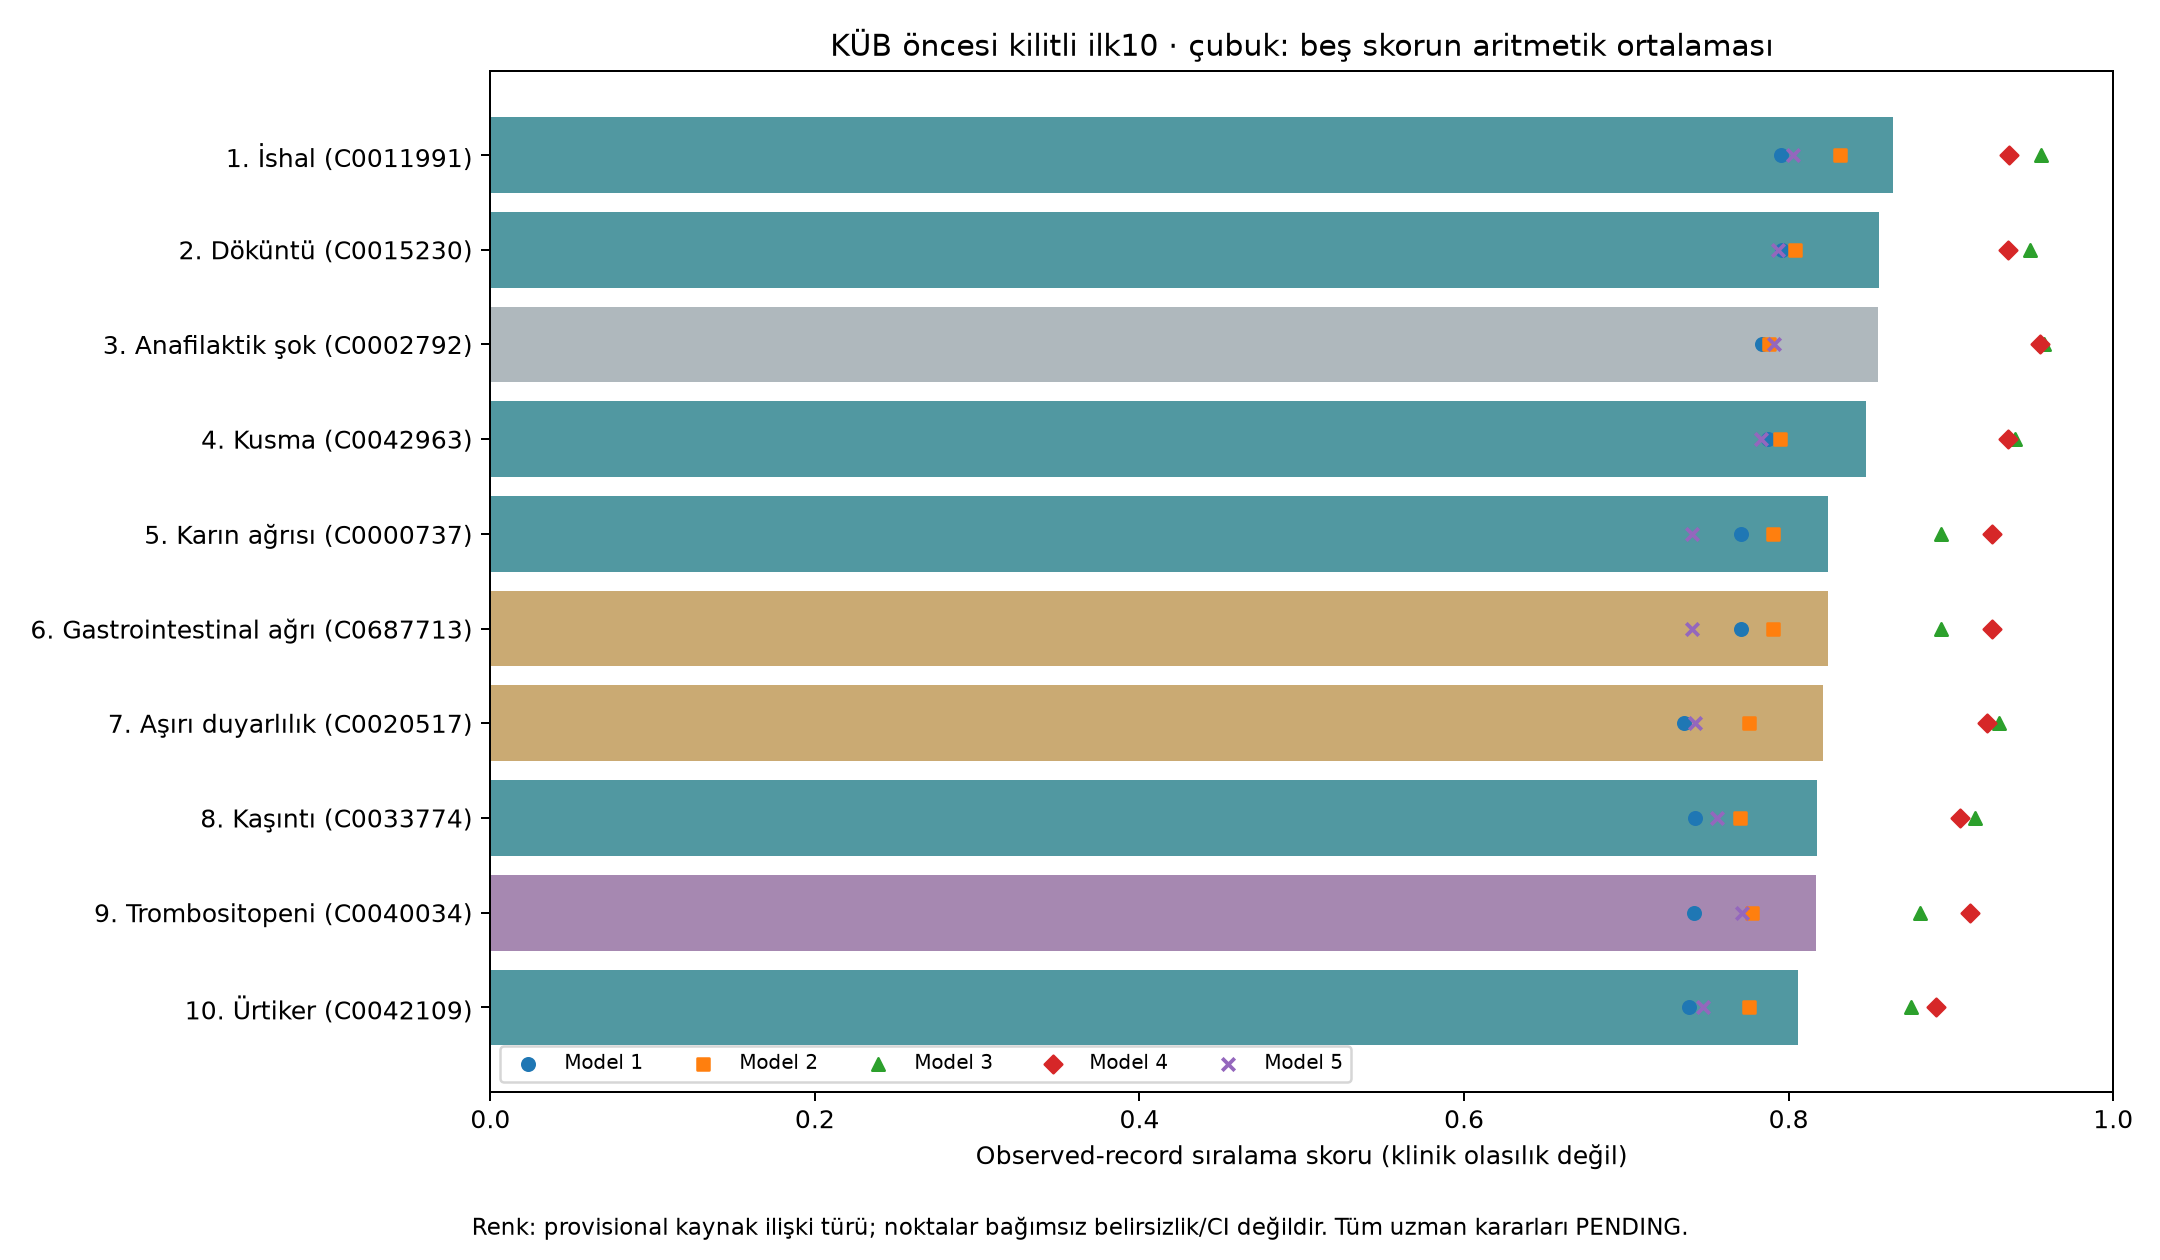

In [2]:
a=pd.read_csv(r.Q/'comparison201.csv',float_precision='round_trip')
t=a.head(10)
display(t)
from IPython.display import Image
display(Image(filename=str(r.F/'01_locked_top10_scores.png')))

**Yorum:** İlk10'un tamamı önceden seçildi.6 çeviri/eşanlam adayı,2 ilişkili, eşdeğerliği doğrulanmamış kavram,1 sınıf uyarısı,1 eşlemesi saptanmayan hedef. Bunlar klinik doğrulanmış doğru/yanlış sayıları değildir. Noktalar beş gerçek skor; CI veya beş bağımsız hasta deneyi değildir.

,rank,class_id,record_ranking_score,drug_id,contributing_models,aggregation,semantics,fold1_score,fold2_score,fold3_score,...,mapping_status,human_review,source_terms,source_pages,quote_ids,relations,source_scopes,frequencies,expert_confirmed_equivalent,reference_absence_is_negative
0,1,C0011991,0.864200,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.795402,0.831542,0.955515,...,PROVISIONAL,PENDING,Diyare,7,SIVEXTRO-v1-p07-498-504,SYNONYM_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın,False,False
1,2,C0015230,0.855534,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.796102,0.804158,0.949028,...,PROVISIONAL,PENDING,Döküntü,7,SIVEXTRO-v1-p07-731-738,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın olmayan,False,False
2,3,C0002792,0.854920,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.783397,0.787826,0.957617,...,UNMAPPED,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,False,False
3,4,C0042963,0.847858,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.787195,0.794642,0.939465,...,PROVISIONAL,PENDING,Kusma,7,SIVEXTRO-v1-p07-516-521,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın,False,False
4,5,C0000737,0.823995,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.770632,0.790163,0.893630,...,PROVISIONAL,PENDING,Karın ağrısı,7,SIVEXTRO-v1-p07-484-496,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,Yaygın olmayan,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
196,197,C0020621,0.196710,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.220357,0.253925,0.096986,...,UNMAPPED,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,False,False
197,198,C0011053,0.177103,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.206025,0.212134,0.081200,...,UNMAPPED,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,False,False
198,199,C1384666,0.177103,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.206025,0.212134,0.081200,...,UNMAPPED,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,False,False
199,200,C0028961,0.170387,DB14569,5,equal_weight_arithmetic_score_mean,SIDER observed-record proxy; unknown NOT biological negative; NOT clinical risk/frequency/calibr...,0.220257,0.240360,0.110823,...,UNMAPPED,PENDING,NaN,NaN,NaN,NaN,NaN,NaN,False,False


,reference_term_id,term_tr,frequency,quote_id,physical_page,candidate_PT_CUIs,candidate_PT_in_common201,has_candidate_top10,relation_types,human_review,unmapped_is_not_model_error
0,ADR-001,Vulvovajinal mikotik enfeksiyon,Yaygın olmayan,SIVEXTRO-v1-p06-2112-2143,6,C0404521 | C1609512,True,False,SOURCE_NARROWER_CANDIDATE | TRANSLATION_CANDIDATE,PENDING,True
1,ADR-002,Fungal enfeksiyon,Yaygın olmayan,SIVEXTRO-v1-p06-2145-2162,6,C0026946,True,False,TRANSLATION_CANDIDATE,PENDING,True
2,ADR-003,Vulvovajinal kandidiyaz,Yaygın olmayan,SIVEXTRO-v1-p06-2164-2187,6,C0006840 | C0700345,True,False,SOURCE_NARROWER_CANDIDATE | TRANSLATION_CANDIDATE,PENDING,True
3,ADR-004,Apse,Yaygın olmayan,SIVEXTRO-v1-p06-2189-2193,6,NaN,False,False,NaN,PENDING,True
4,ADR-005,Klostridiyum difisil kolit,Yaygın olmayan,SIVEXTRO-v1-p06-2195-2221,6,C1257843 | C0009319 | C0238106,True,False,RELATED_DISTINCT | SOURCE_NARROWER_CANDIDATE | TRANSLATION_CANDIDATE,PENDING,True
...,...,...,...,...,...,...,...,...,...,...,...
71,ADR-072,İnfüzyonla ilişkili reaksiyon,Yaygın olmayan,SIVEXTRO-v1-p08-165-194,8,NaN,False,False,NaN,PENDING,True
72,ADR-073,Periferik ödem,Yaygın olmayan,SIVEXTRO-v1-p08-196-210,8,C0013604 | C0085649,True,False,SOURCE_NARROWER_CANDIDATE | TRANSLATION_CANDIDATE,PENDING,True
73,ADR-074,Kavrama gücünde azalma,Yaygın olmayan,SIVEXTRO-v1-p08-228-250,8,NaN,False,False,NaN,PENDING,True
74,ADR-075,Transaminaz artışı,Yaygın olmayan,SIVEXTRO-v1-p08-252-270,8,C0151904 | C0151905,True,False,TARGET_NARROWER_CANDIDATE,PENDING,True


,reference_term_id,term_tr,frequency,quote_id,physical_page,candidate_PT_CUIs,candidate_PT_in_common201,has_candidate_top10,relation_types,human_review,unmapped_is_not_model_error
0,ADR-001,Vulvovajinal mikotik enfeksiyon,Yaygın olmayan,SIVEXTRO-v1-p06-2112-2143,6,C0404521 | C1609512,True,False,SOURCE_NARROWER_CANDIDATE | TRANSLATION_CANDIDATE,PENDING,True
1,ADR-002,Fungal enfeksiyon,Yaygın olmayan,SIVEXTRO-v1-p06-2145-2162,6,C0026946,True,False,TRANSLATION_CANDIDATE,PENDING,True
2,ADR-003,Vulvovajinal kandidiyaz,Yaygın olmayan,SIVEXTRO-v1-p06-2164-2187,6,C0006840 | C0700345,True,False,SOURCE_NARROWER_CANDIDATE | TRANSLATION_CANDIDATE,PENDING,True
3,ADR-004,Apse,Yaygın olmayan,SIVEXTRO-v1-p06-2189-2193,6,NaN,False,False,NaN,PENDING,True
4,ADR-005,Klostridiyum difisil kolit,Yaygın olmayan,SIVEXTRO-v1-p06-2195-2221,6,C1257843 | C0009319 | C0238106,True,False,RELATED_DISTINCT | SOURCE_NARROWER_CANDIDATE | TRANSLATION_CANDIDATE,PENDING,True
5,ADR-006,Dermatofitoz,Yaygın olmayan,SIVEXTRO-v1-p06-2223-2235,6,C0011630,True,False,SOURCE_NARROWER_CANDIDATE,PENDING,True
6,ADR-007,Oral kandidiyaz,Yaygın olmayan,SIVEXTRO-v1-p06-2237-2252,6,C0006840 | C0006849,True,False,SOURCE_NARROWER_CANDIDATE | TRANSLATION_CANDIDATE,PENDING,True
7,ADR-008,Solunum yolu enfeksiyonu,Yaygın olmayan,SIVEXTRO-v1-p06-2254-2278,6,C0041912,True,False,TARGET_NARROWER_CANDIDATE,PENDING,True
8,ADR-009,Lenfadenopati,Yaygın olmayan,SIVEXTRO-v1-p06-2319-2332,6,NaN,False,False,NaN,PENDING,True
9,ADR-011,Dehidratasyon,Yaygın olmayan,SIVEXTRO-v1-p06-2435-2448,6,NaN,False,False,NaN,PENDING,True


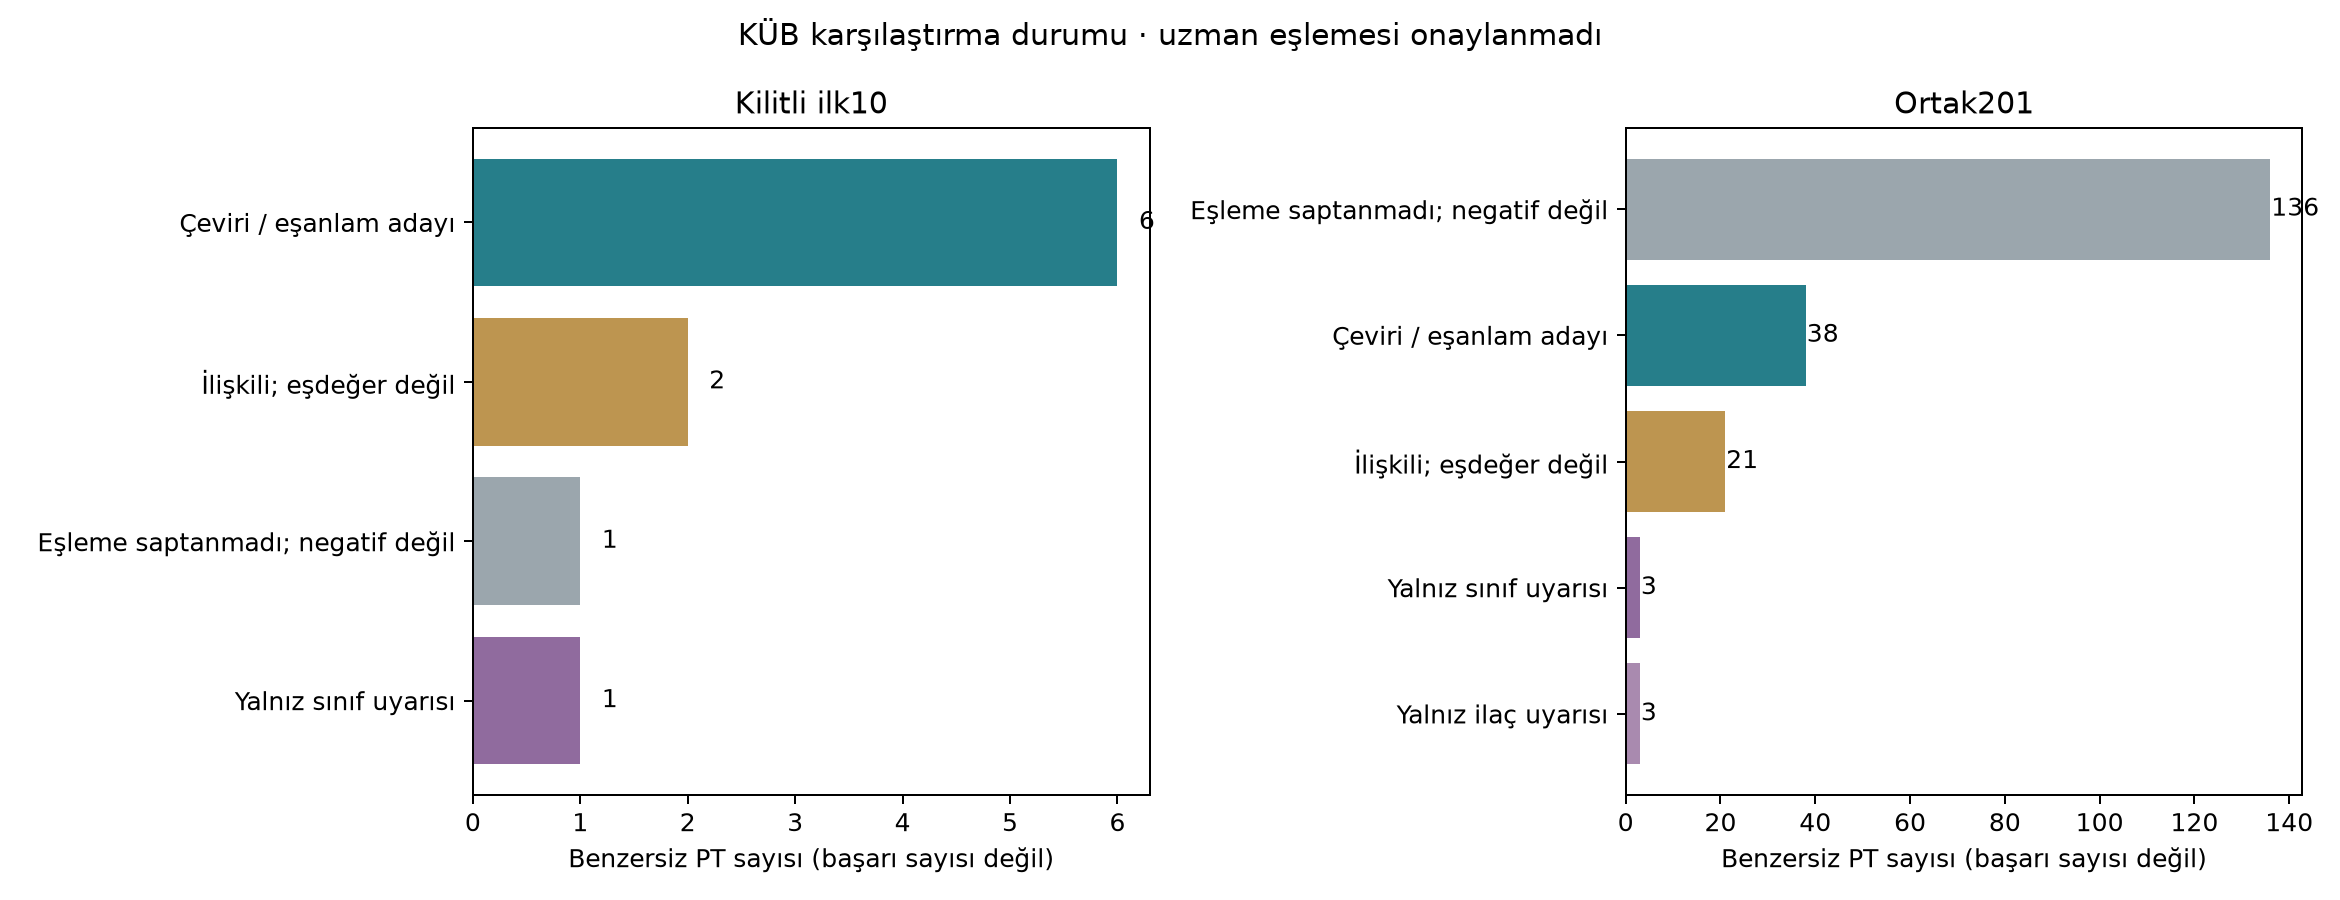

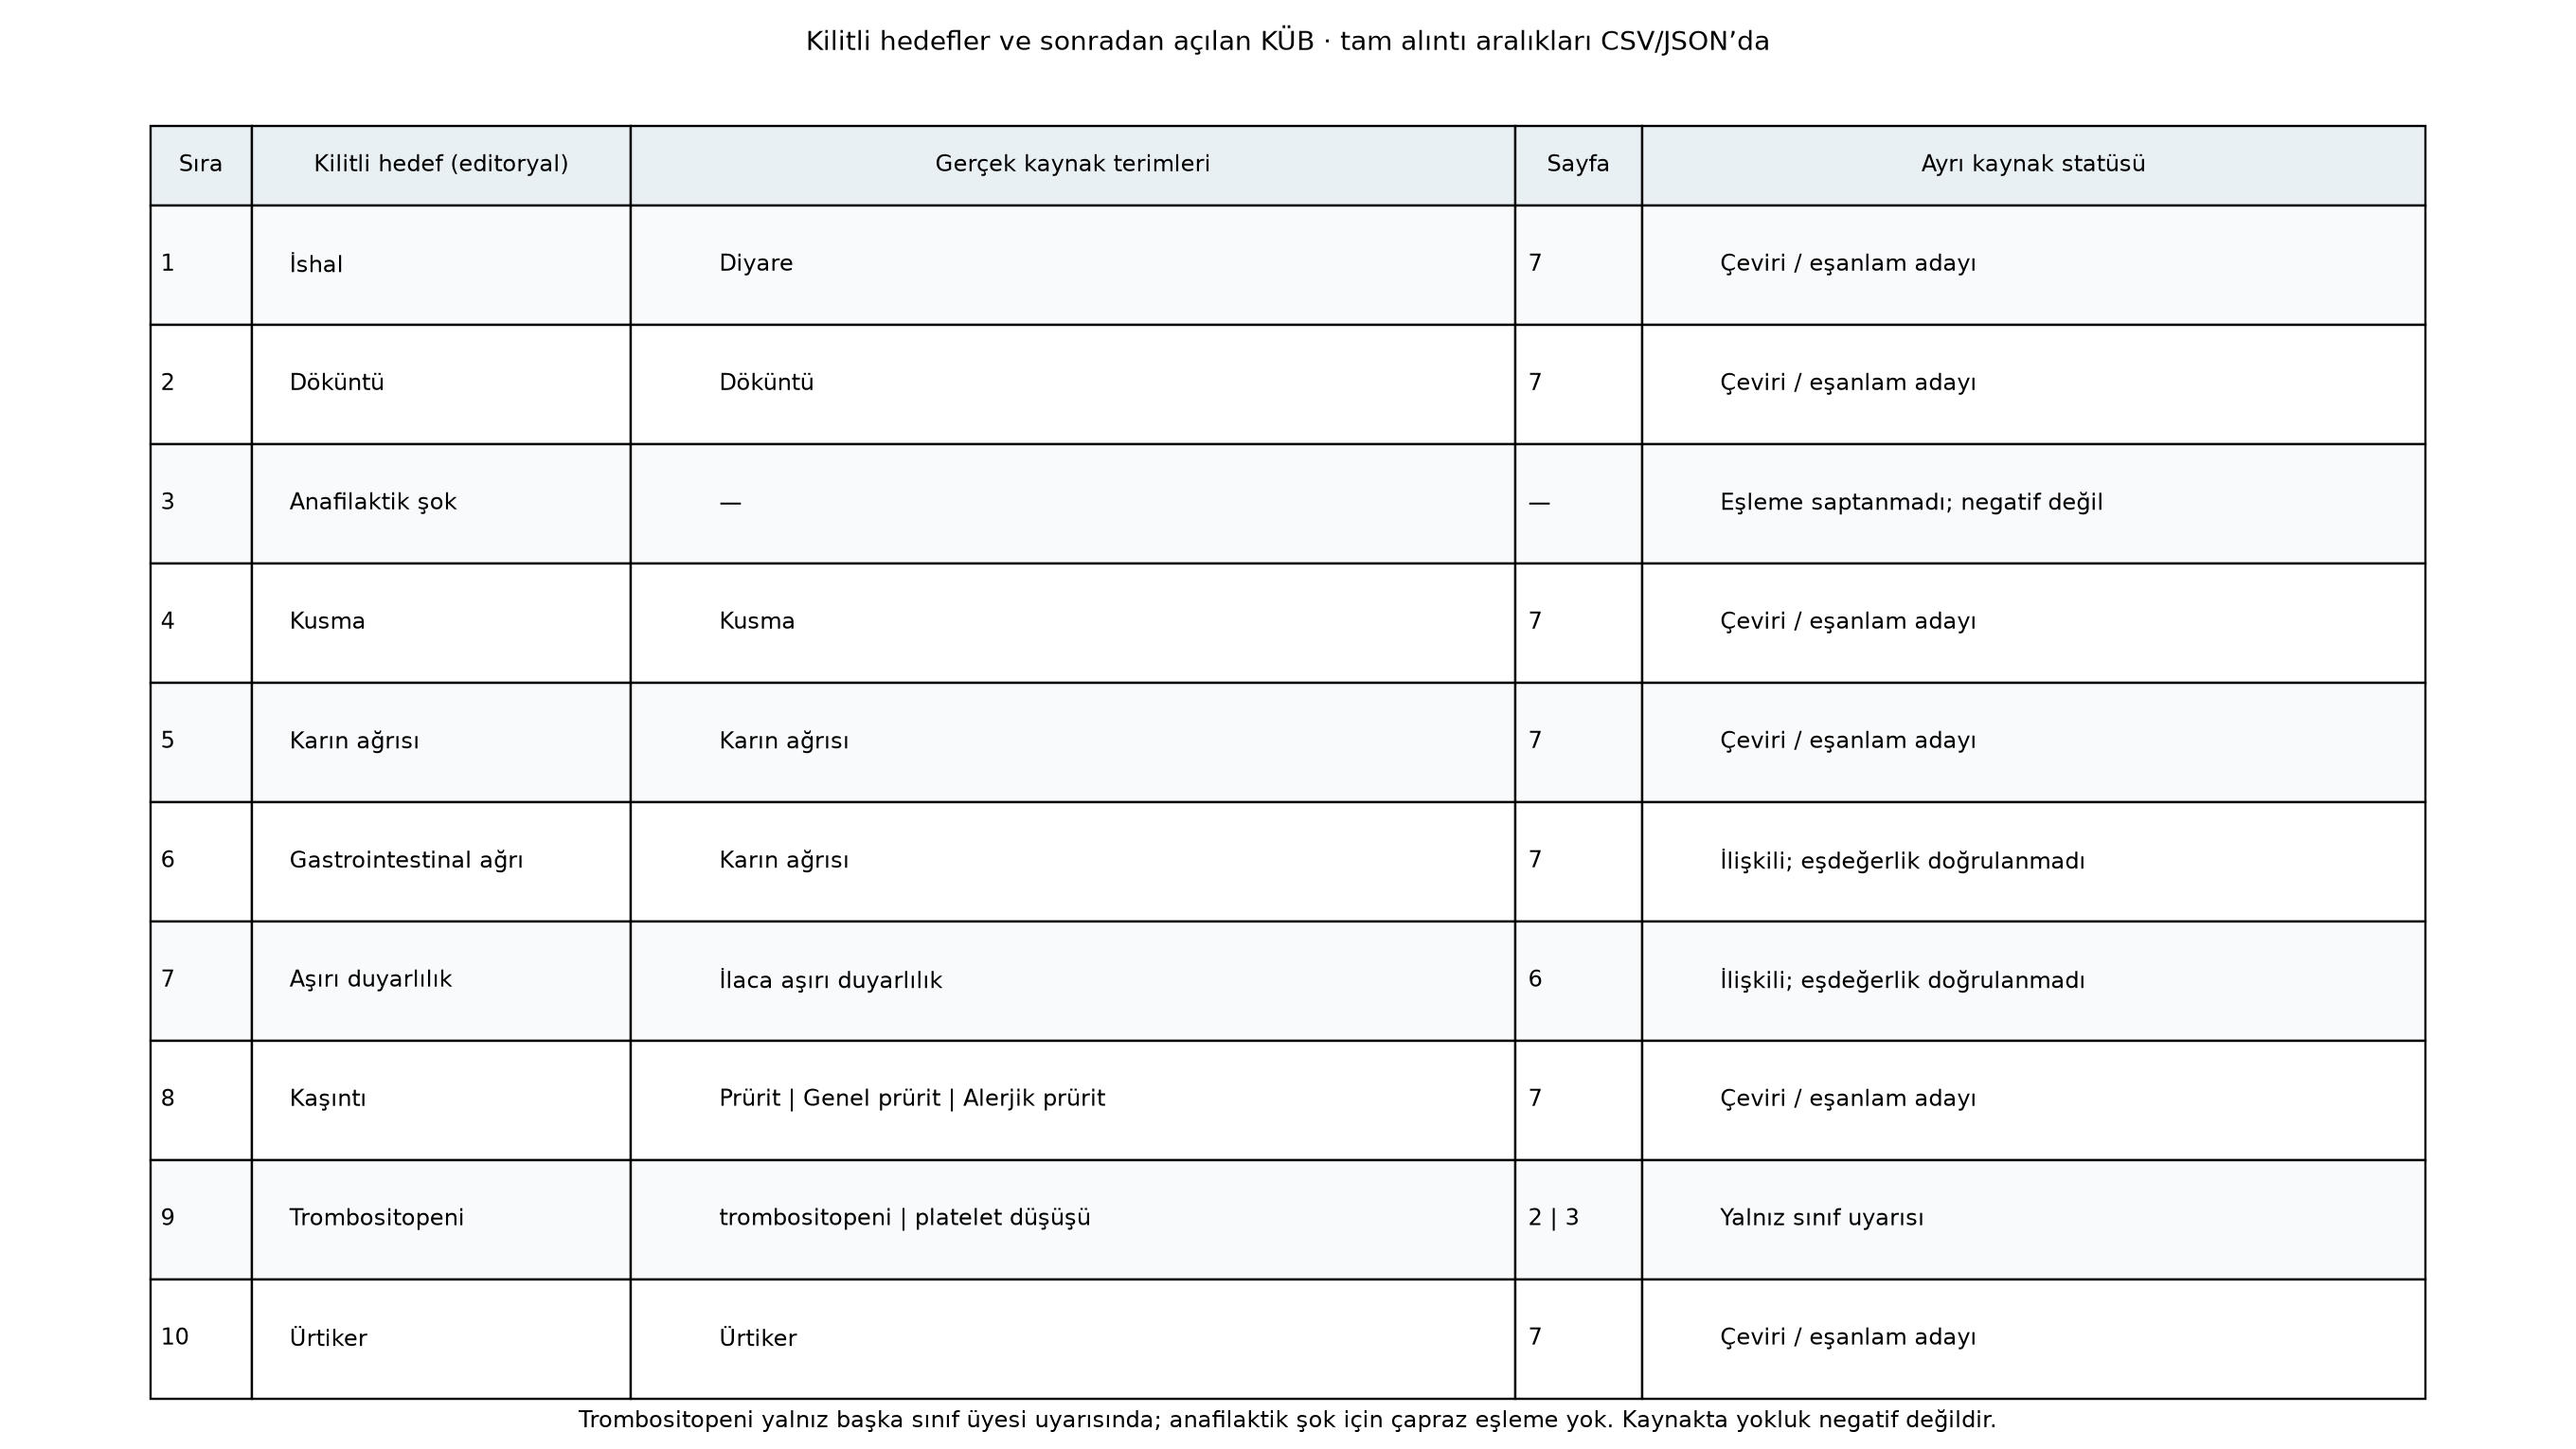

In [3]:
display(a)
display(pd.read_csv(r.Q/'all_reference_terms_target_coverage.csv'))
display(pd.read_csv(r.Q/'reference_terms_outside_top10.csv'))
display(Image(filename=str(r.F/'02_source_scope_counts.png')))
display(Image(filename=str(r.F/'03_source_target_comparison.png')))

**Yorum:** 76 özgün tablo hücresi:7 yaygın/69 yaygın olmayan.67 kaynak teriminin ilk10 içinde anotasyon adayı yoktur; bunlar yanlış negatif değildir.38 ortak PT'de çeviri/eşanlam adayı,21'de yalnız ilişkili terim,3'te sınıf uyarısı,3'te ilaç uyarısı,136'da anotasyon saptanmadı. Terim ilişkileri çoktan çoğa olabilir; aynı olay bağımsız kanıt gibi sayılmaz. Bulantı gibi kaynak olayları ortak201'in kapsamı dışında kalabilir.

1 İshal C0011991
2 Döküntü C0015230
3 Anafilaktik şok C0002792
4 Kusma C0042963
5 Karın ağrısı C0000737
6 Gastrointestinal ağrı C0687713
7 Aşırı duyarlılık C0020517
8 Kaşıntı C0033774
9 Trombositopeni C0040034
10 Ürtiker C0042109


,drug_id,fold,model,class_id,term,term_tr_editorial,base_logit,sum_phi,locked_logit,locked_record_score,additivity_error,sigmoid_check_error,n_background_train,scale,model_sha256,pre_explanation_sha256
0,DB14569,1,B1,C0011991,Diarrhoea,İshal,1.202839,0.154960,1.357799,0.795402,0.000000e+00,0,43,B1 per-model logit; not ensemble,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,10561e51dc048db1e5838ad3a026aec21744df110c11edd90456715de3d95343
1,DB14569,1,B1,C0015230,Rash,Döküntü,1.362910,-0.000804,1.362106,0.796102,2.220446e-16,0,43,B1 per-model logit; not ensemble,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,10561e51dc048db1e5838ad3a026aec21744df110c11edd90456715de3d95343
2,DB14569,1,B1,C0002792,Anaphylactic shock,Anafilaktik şok,1.128291,0.157282,1.285574,0.783397,0.000000e+00,0,43,B1 per-model logit; not ensemble,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,10561e51dc048db1e5838ad3a026aec21744df110c11edd90456715de3d95343
3,DB14569,1,B1,C0042963,Vomiting,Kusma,1.283219,0.024883,1.308102,0.787195,0.000000e+00,0,43,B1 per-model logit; not ensemble,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,10561e51dc048db1e5838ad3a026aec21744df110c11edd90456715de3d95343
4,DB14569,1,B1,C0000737,Abdominal pain,Karın ağrısı,0.912119,0.299763,1.211882,0.770632,0.000000e+00,0,43,B1 per-model logit; not ensemble,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,10561e51dc048db1e5838ad3a026aec21744df110c11edd90456715de3d95343
5,DB14569,1,B1,C0687713,Gastrointestinal pain,Gastrointestinal ağrı,0.912119,0.299763,1.211882,0.770632,0.000000e+00,0,43,B1 per-model logit; not ensemble,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,10561e51dc048db1e5838ad3a026aec21744df110c11edd90456715de3d95343
6,DB14569,1,B1,C0020517,Hypersensitivity,Aşırı duyarlılık,1.059462,-0.038122,1.021339,0.735233,0.000000e+00,0,43,B1 per-model logit; not ensemble,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,10561e51dc048db1e5838ad3a026aec21744df110c11edd90456715de3d95343
7,DB14569,1,B1,C0033774,Pruritus,Kaşıntı,0.981805,0.075498,1.057303,0.742175,0.000000e+00,0,43,B1 per-model logit; not ensemble,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,10561e51dc048db1e5838ad3a026aec21744df110c11edd90456715de3d95343
8,DB14569,1,B1,C0040034,Thrombocytopenia,Trombositopeni,0.906054,0.147742,1.053796,0.741503,0.000000e+00,0,43,B1 per-model logit; not ensemble,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,10561e51dc048db1e5838ad3a026aec21744df110c11edd90456715de3d95343
9,DB14569,1,B1,C0042109,Urticaria,Ürtiker,0.984532,0.053657,1.038189,0.738500,0.000000e+00,0,43,B1 per-model logit; not ensemble,ea967157b1fce12de80577d1c7017bd0a9dc4e589e965ae1b09adcb351fffc7d,10561e51dc048db1e5838ad3a026aec21744df110c11edd90456715de3d95343


,drug_id,fold,model,class_id,term,term_tr_editorial,feature,feature_name_tr,feature_type,raw_value,standardized_query,background_mean_standardized,coefficient,SHAP_logit,comment_tr
0,DB14569,1,B1,C0011991,Diarrhoea,İshal,chem__MW,Molekül ağırlığı,chemistry,370.3440,-0.354909,-6.325689e-17,-0.017359,0.006161,Molekül ağırlığı: SHAP=0.006160931723496939; bu B1 modelinde train-only background’a göre logiti...
1,DB14569,1,B1,C0011991,Diarrhoea,İshal,chem__LogP,LogP,chemistry,1.3957,0.407551,1.549148e-17,0.080976,0.033002,LogP: SHAP=0.03300201215890247; bu B1 modelinde train-only background’a göre logiti artırıcı yön...
2,DB14569,1,B1,C0011991,Diarrhoea,İshal,chem__HBD,Hidrojen bağı verici sayısı,chemistry,1.0000,-0.734164,-9.682178e-18,-0.131061,0.096220,Hidrojen bağı verici sayısı: SHAP=0.09622034541489968; bu B1 modelinde train-only background’a g...
3,DB14569,1,B1,C0011991,Diarrhoea,İshal,chem__HBA,Hidrojen bağı alıcı sayısı,chemistry,7.0000,-0.322181,7.616646e-17,0.018155,-0.005849,Hidrojen bağı alıcı sayısı: SHAP=-0.005849215876346629; bu B1 modelinde train-only background’a ...
4,DB14569,1,B1,C0011991,Diarrhoea,İshal,chem__TPSA,Topolojik polar yüzey alanı,chemistry,106.2600,-0.523607,-1.591105e-16,-0.048559,0.025426,Topolojik polar yüzey alanı: SHAP=0.025425854228556245; bu B1 modelinde train-only background’a ...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
295,DB14569,5,B1,C0042109,Urticaria,Ürtiker,chem__LogP,LogP,chemistry,1.3957,0.445021,-1.871888e-17,0.353714,0.157410,LogP: SHAP=0.15741012481587946; bu B1 modelinde train-only background’a göre logiti artırıcı yön...
296,DB14569,5,B1,C0042109,Urticaria,Ürtiker,chem__HBD,Hidrojen bağı verici sayısı,chemistry,1.0000,-0.790710,1.710518e-17,-0.105720,0.083594,Hidrojen bağı verici sayısı: SHAP=0.08359427729929197; bu B1 modelinde train-only background’a g...
297,DB14569,5,B1,C0042109,Urticaria,Ürtiker,chem__HBA,Hidrojen bağı alıcı sayısı,chemistry,7.0000,-0.346291,1.807340e-17,0.068630,-0.023766,Hidrojen bağı alıcı sayısı: SHAP=-0.02376593226578873; bu B1 modelinde train-only background’a g...
298,DB14569,5,B1,C0042109,Urticaria,Ürtiker,chem__TPSA,Topolojik polar yüzey alanı,chemistry,106.2600,-0.539387,0.000000e+00,-0.023093,0.012456,Topolojik polar yüzey alanı: SHAP=0.012456291491126124; bu B1 modelinde train-only background’a ...


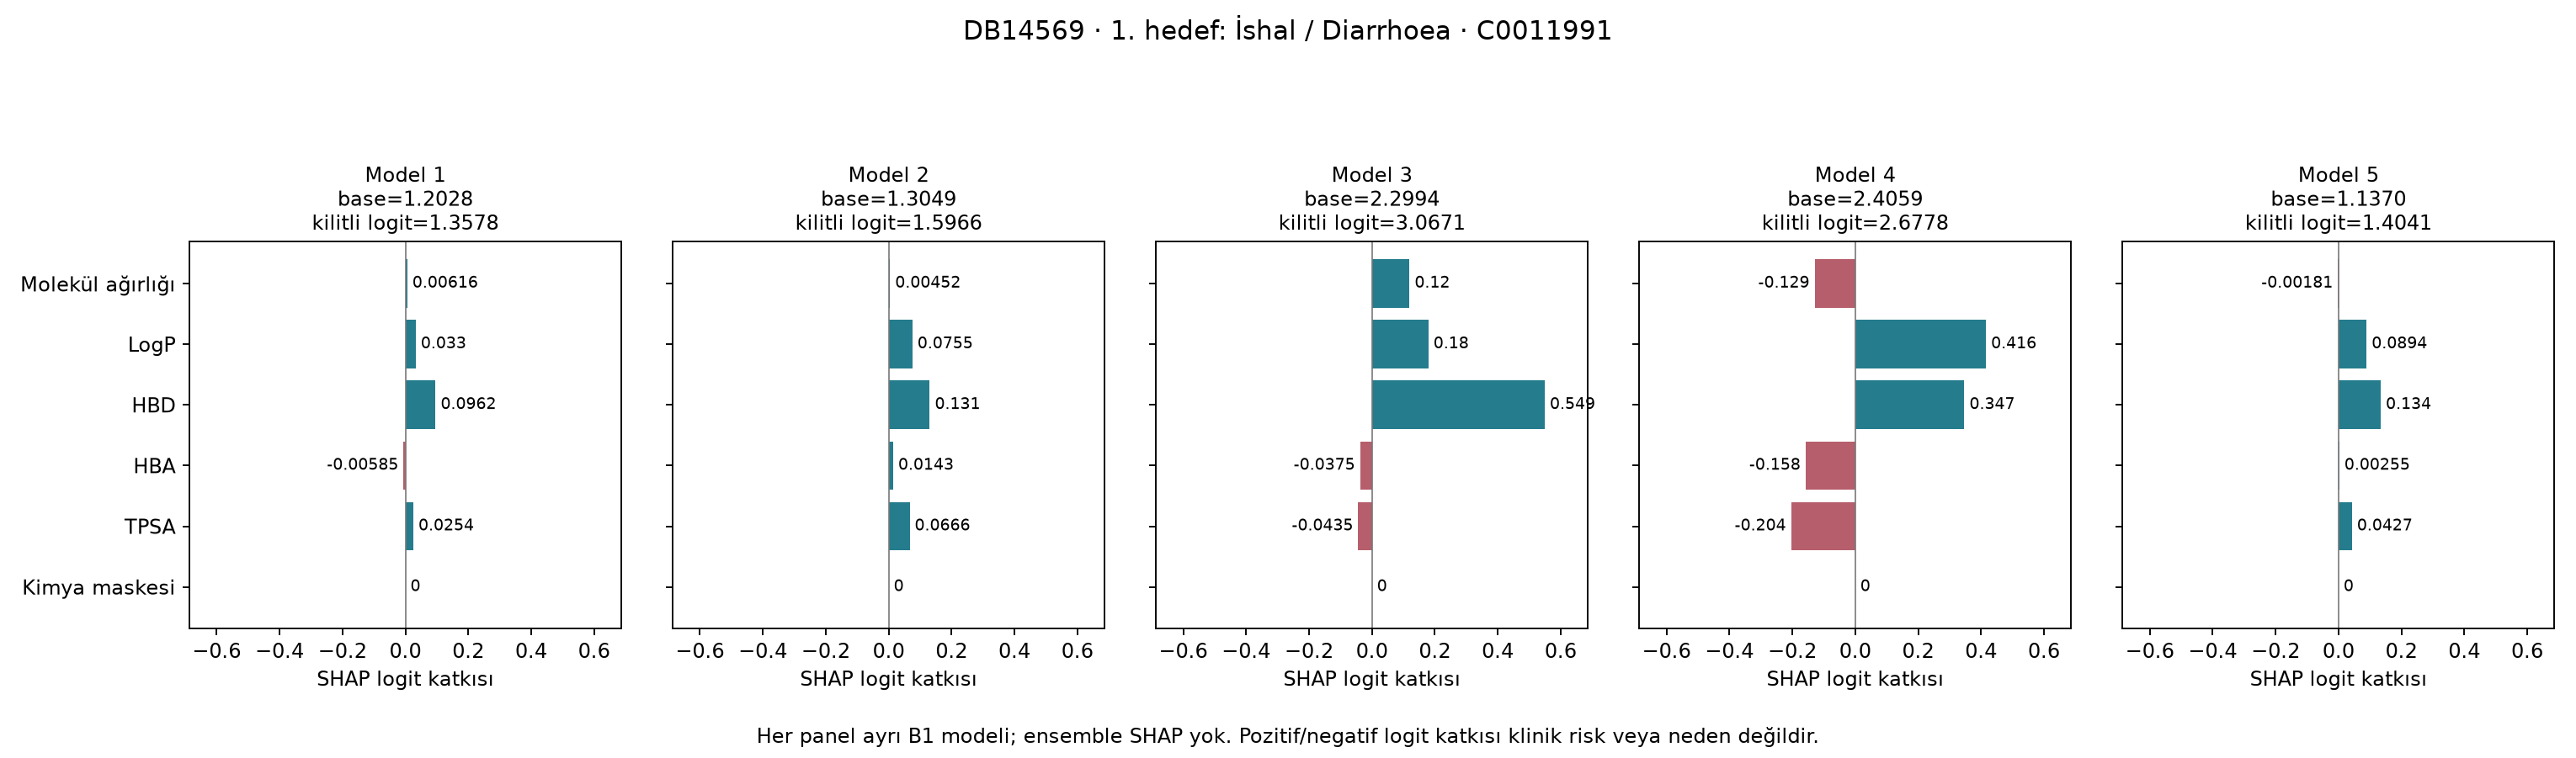

,class_id,term,term_tr_editorial,fold,explanation_tr
0,C0011991,Diarrhoea,İshal,1,"B1 primary model1, İshal (Diarrhoea): train-only background’a göre logiti artırıcı kimyasal katk..."
1,C0011991,Diarrhoea,İshal,2,"B1 primary model2, İshal (Diarrhoea): train-only background’a göre logiti artırıcı kimyasal katk..."
2,C0011991,Diarrhoea,İshal,3,"B1 primary model3, İshal (Diarrhoea): train-only background’a göre logiti artırıcı kimyasal katk..."
3,C0011991,Diarrhoea,İshal,4,"B1 primary model4, İshal (Diarrhoea): train-only background’a göre logiti artırıcı kimyasal katk..."
4,C0011991,Diarrhoea,İshal,5,"B1 primary model5, İshal (Diarrhoea): train-only background’a göre logiti artırıcı kimyasal katk..."


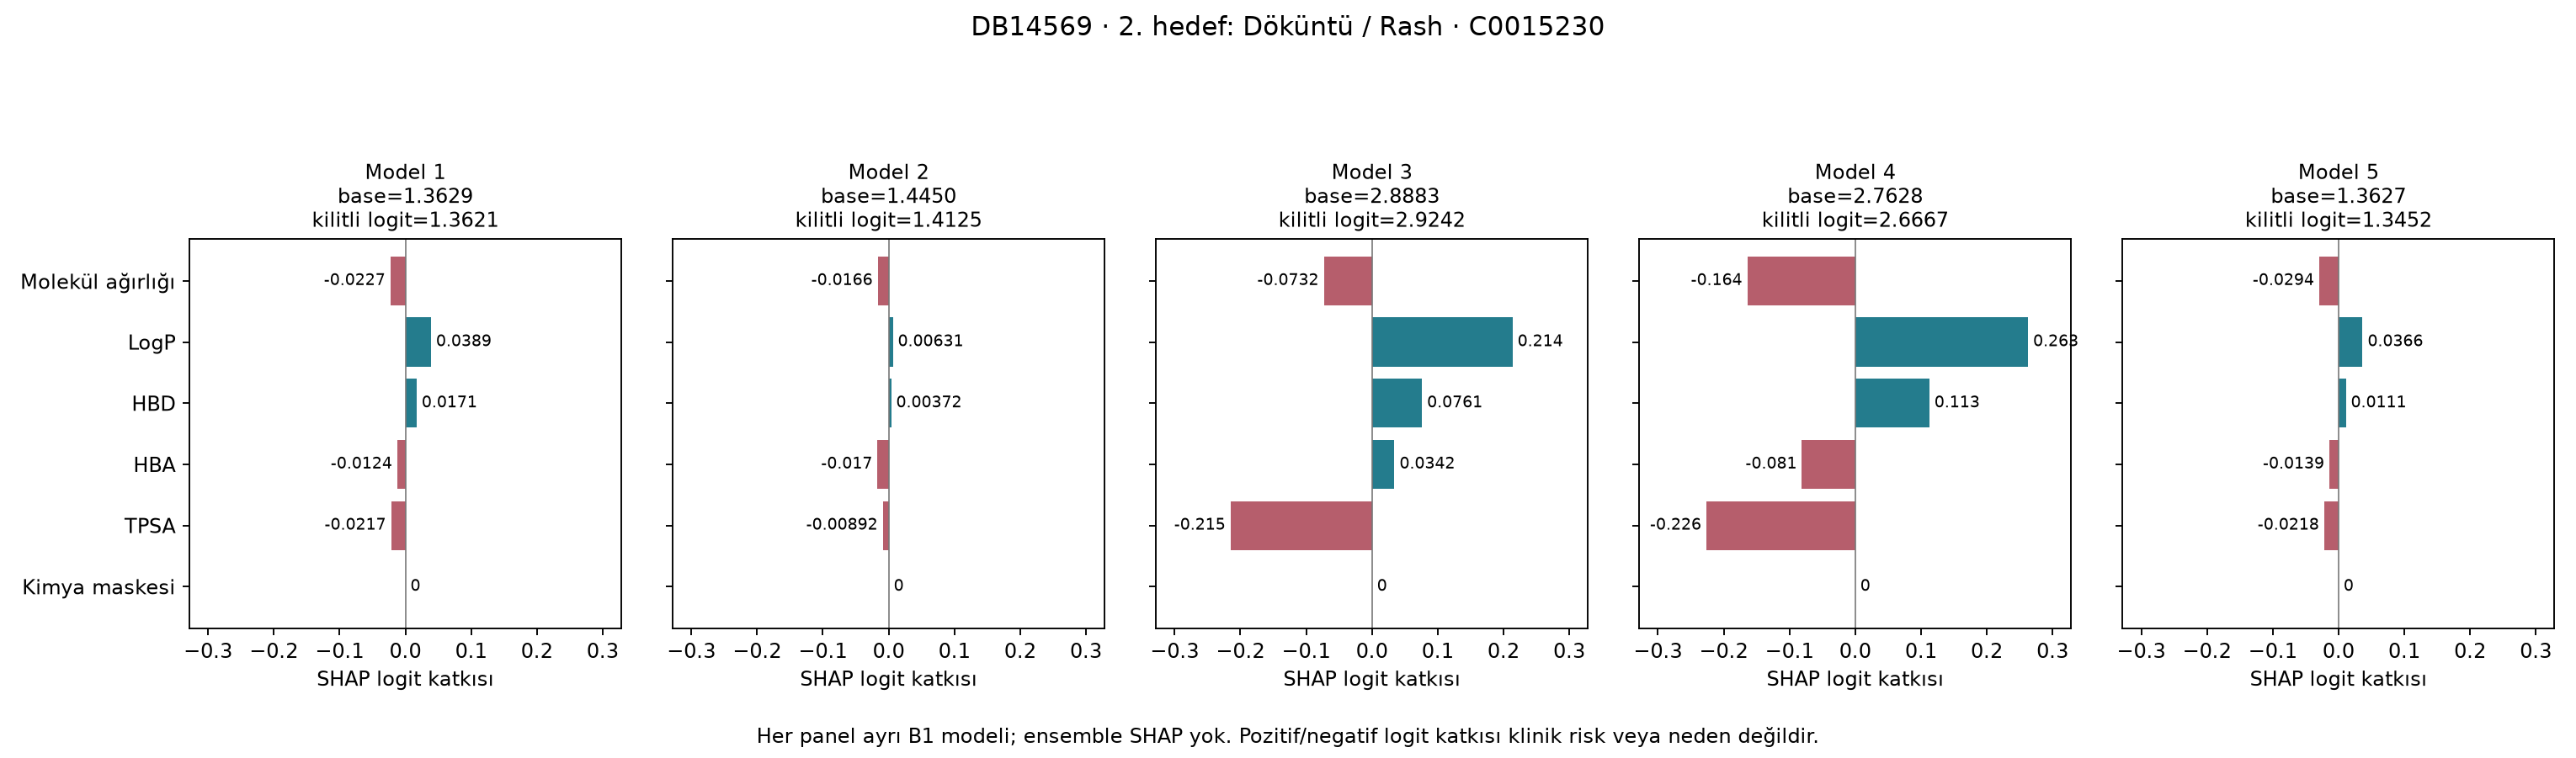

,class_id,term,term_tr_editorial,fold,explanation_tr
0,C0015230,Rash,Döküntü,1,"B1 primary model1, Döküntü (Rash): train-only background’a göre logiti artırıcı kimyasal katkıla..."
1,C0015230,Rash,Döküntü,2,"B1 primary model2, Döküntü (Rash): train-only background’a göre logiti artırıcı kimyasal katkıla..."
2,C0015230,Rash,Döküntü,3,"B1 primary model3, Döküntü (Rash): train-only background’a göre logiti artırıcı kimyasal katkıla..."
3,C0015230,Rash,Döküntü,4,"B1 primary model4, Döküntü (Rash): train-only background’a göre logiti artırıcı kimyasal katkıla..."
4,C0015230,Rash,Döküntü,5,"B1 primary model5, Döküntü (Rash): train-only background’a göre logiti artırıcı kimyasal katkıla..."


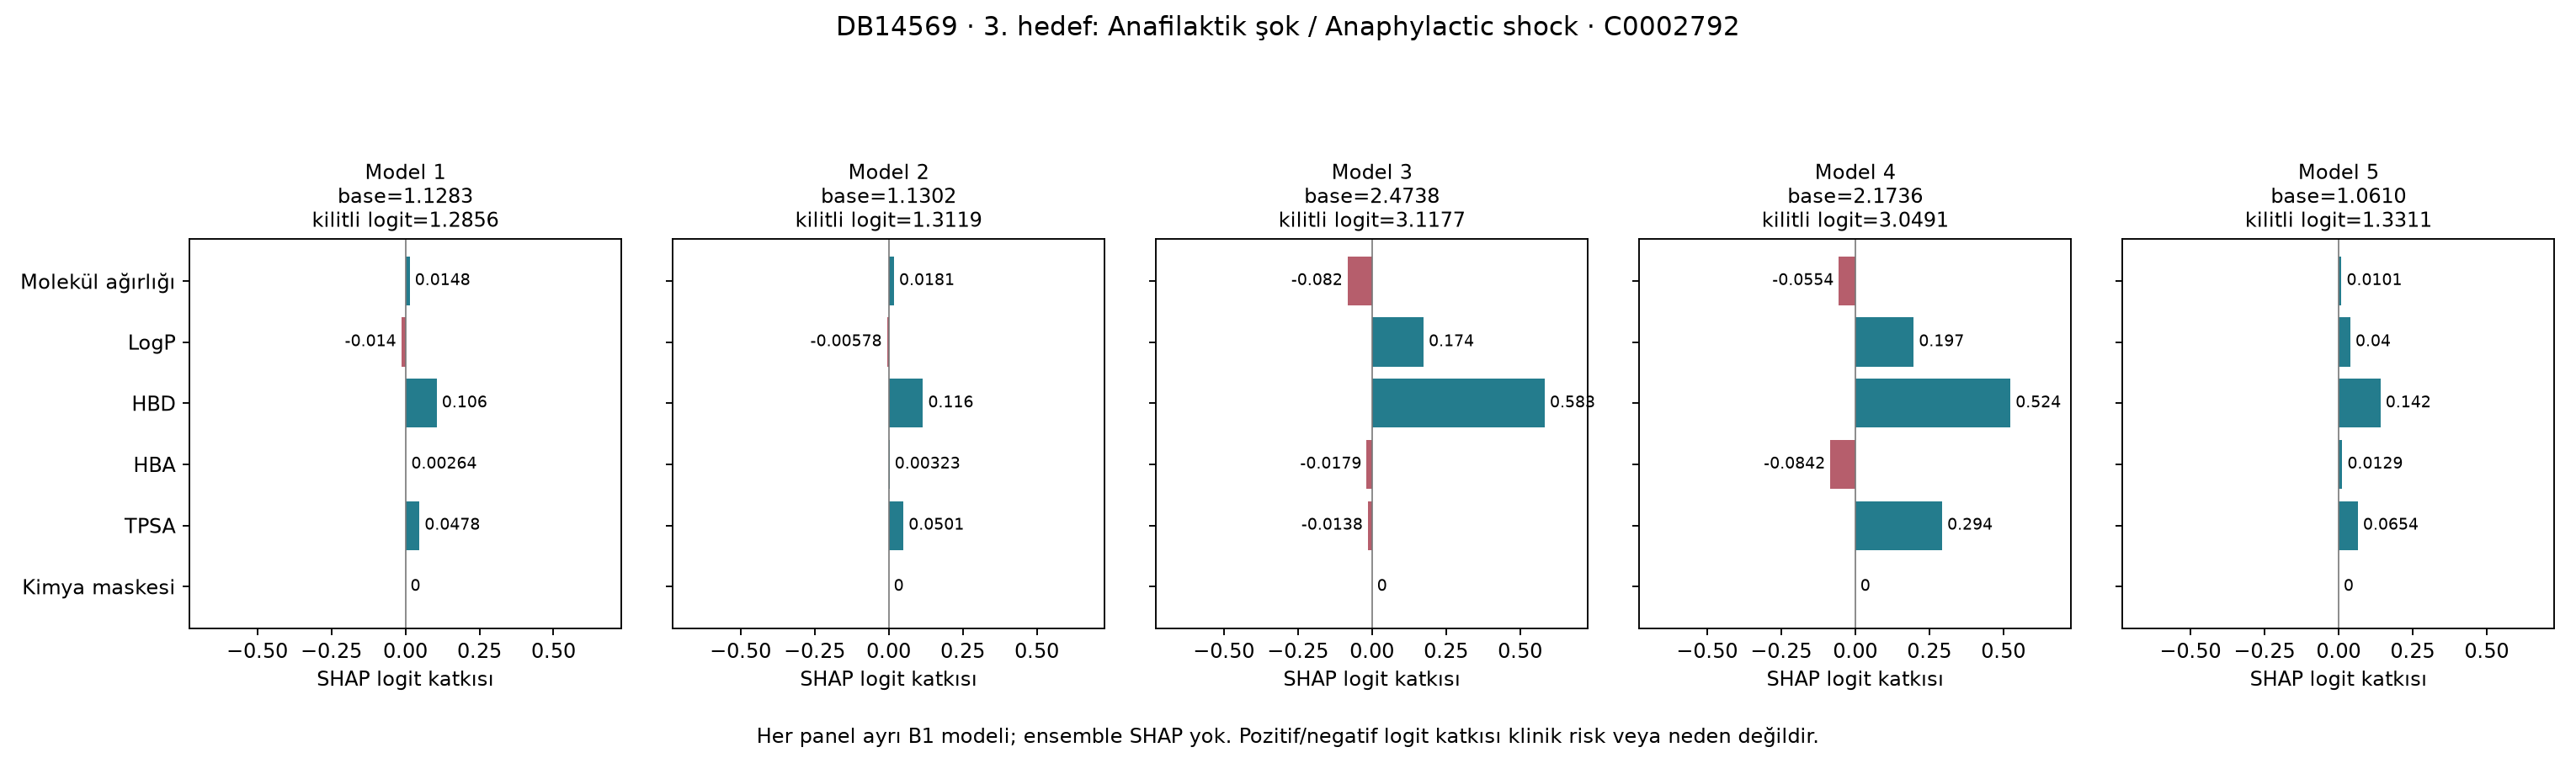

,class_id,term,term_tr_editorial,fold,explanation_tr
0,C0002792,Anaphylactic shock,Anafilaktik şok,1,"B1 primary model1, Anafilaktik şok (Anaphylactic shock): train-only background’a göre logiti art..."
1,C0002792,Anaphylactic shock,Anafilaktik şok,2,"B1 primary model2, Anafilaktik şok (Anaphylactic shock): train-only background’a göre logiti art..."
2,C0002792,Anaphylactic shock,Anafilaktik şok,3,"B1 primary model3, Anafilaktik şok (Anaphylactic shock): train-only background’a göre logiti art..."
3,C0002792,Anaphylactic shock,Anafilaktik şok,4,"B1 primary model4, Anafilaktik şok (Anaphylactic shock): train-only background’a göre logiti art..."
4,C0002792,Anaphylactic shock,Anafilaktik şok,5,"B1 primary model5, Anafilaktik şok (Anaphylactic shock): train-only background’a göre logiti art..."


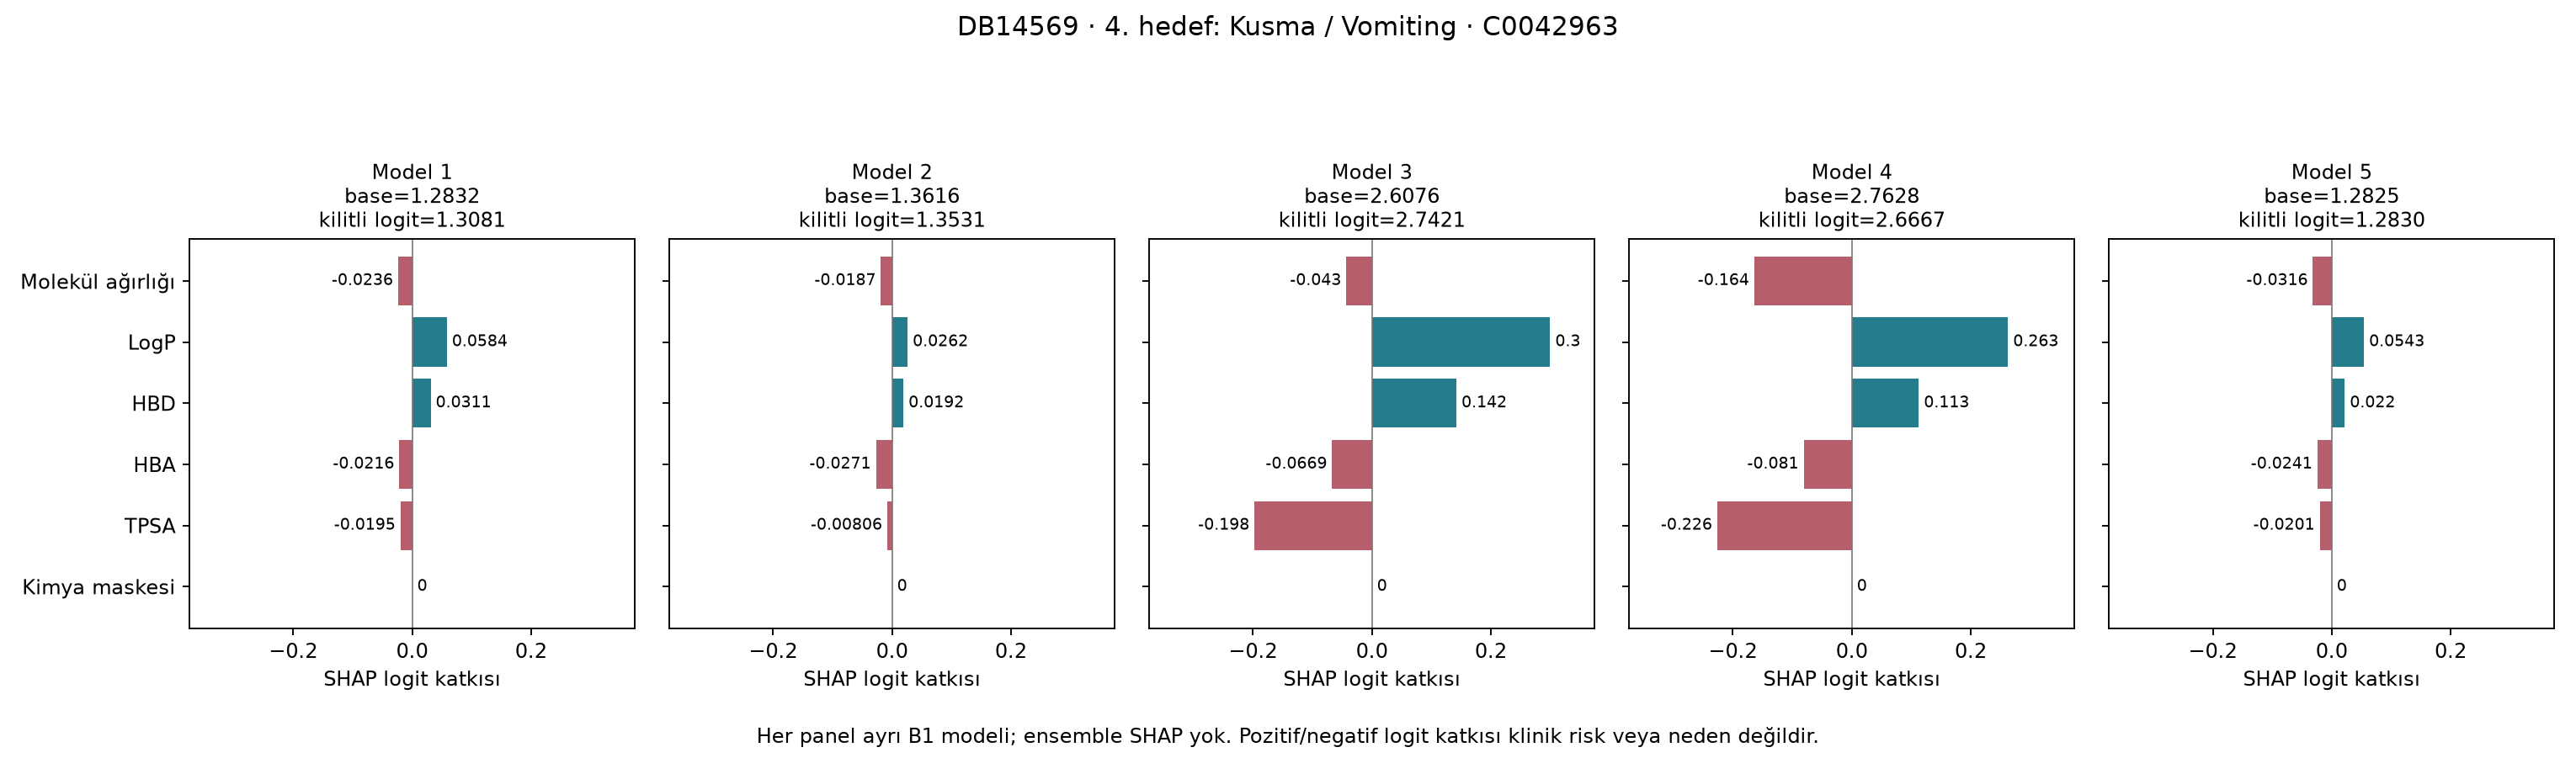

,class_id,term,term_tr_editorial,fold,explanation_tr
0,C0042963,Vomiting,Kusma,1,"B1 primary model1, Kusma (Vomiting): train-only background’a göre logiti artırıcı kimyasal katkı..."
1,C0042963,Vomiting,Kusma,2,"B1 primary model2, Kusma (Vomiting): train-only background’a göre logiti artırıcı kimyasal katkı..."
2,C0042963,Vomiting,Kusma,3,"B1 primary model3, Kusma (Vomiting): train-only background’a göre logiti artırıcı kimyasal katkı..."
3,C0042963,Vomiting,Kusma,4,"B1 primary model4, Kusma (Vomiting): train-only background’a göre logiti artırıcı kimyasal katkı..."
4,C0042963,Vomiting,Kusma,5,"B1 primary model5, Kusma (Vomiting): train-only background’a göre logiti artırıcı kimyasal katkı..."


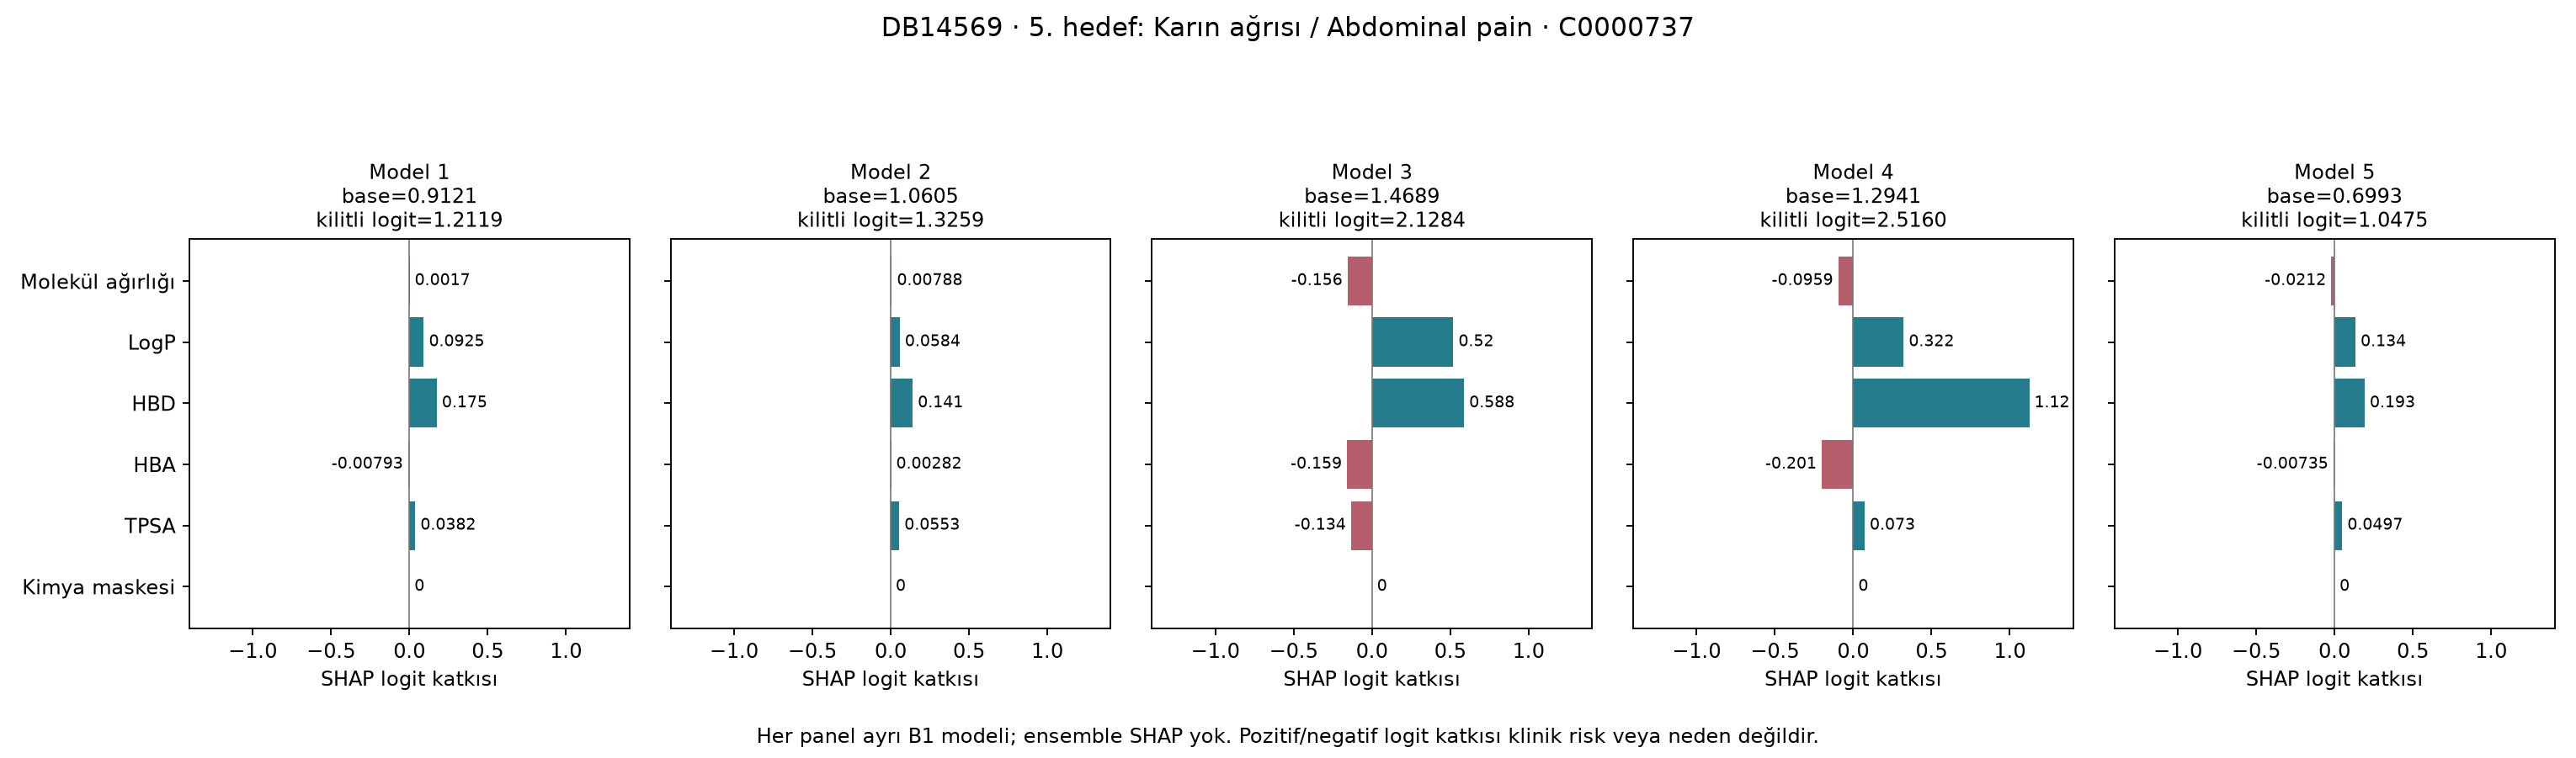

,class_id,term,term_tr_editorial,fold,explanation_tr
0,C0000737,Abdominal pain,Karın ağrısı,1,"B1 primary model1, Karın ağrısı (Abdominal pain): train-only background’a göre logiti artırıcı k..."
1,C0000737,Abdominal pain,Karın ağrısı,2,"B1 primary model2, Karın ağrısı (Abdominal pain): train-only background’a göre logiti artırıcı k..."
2,C0000737,Abdominal pain,Karın ağrısı,3,"B1 primary model3, Karın ağrısı (Abdominal pain): train-only background’a göre logiti artırıcı k..."
3,C0000737,Abdominal pain,Karın ağrısı,4,"B1 primary model4, Karın ağrısı (Abdominal pain): train-only background’a göre logiti artırıcı k..."
4,C0000737,Abdominal pain,Karın ağrısı,5,"B1 primary model5, Karın ağrısı (Abdominal pain): train-only background’a göre logiti artırıcı k..."


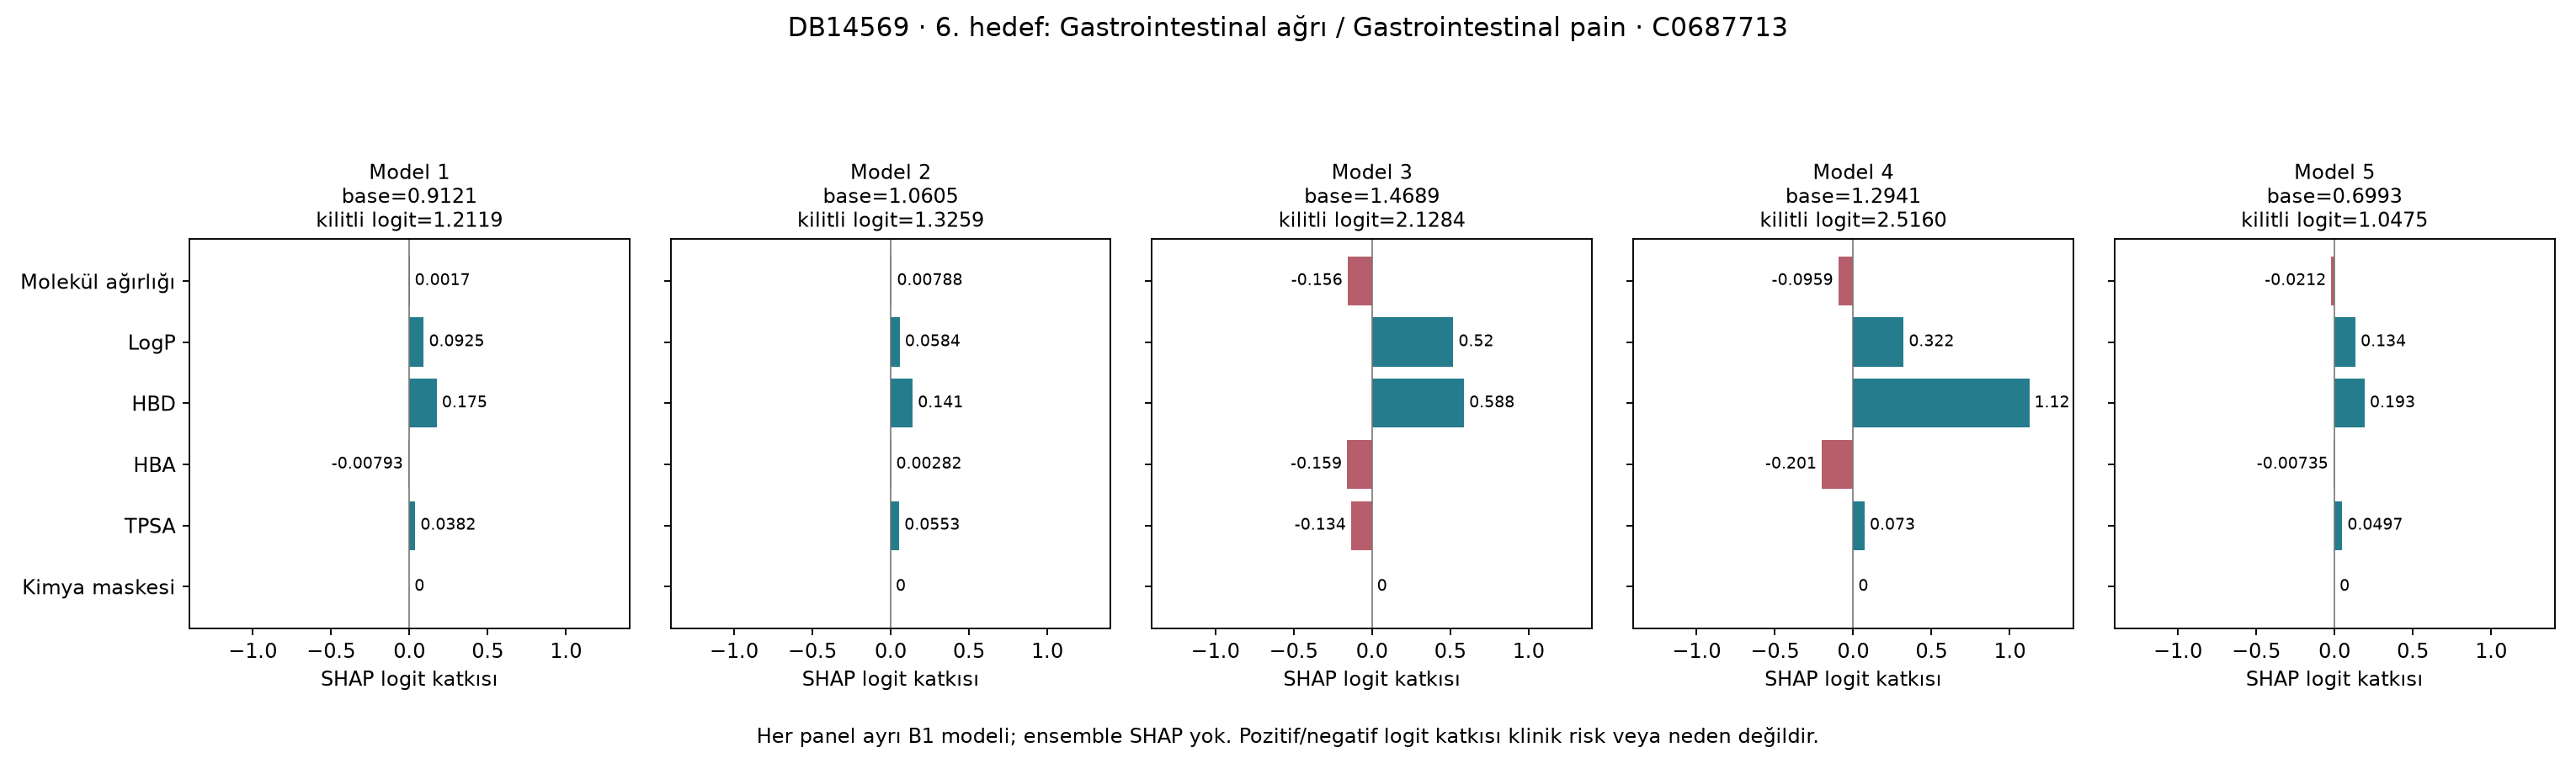

,class_id,term,term_tr_editorial,fold,explanation_tr
0,C0687713,Gastrointestinal pain,Gastrointestinal ağrı,1,"B1 primary model1, Gastrointestinal ağrı (Gastrointestinal pain): train-only background’a göre l..."
1,C0687713,Gastrointestinal pain,Gastrointestinal ağrı,2,"B1 primary model2, Gastrointestinal ağrı (Gastrointestinal pain): train-only background’a göre l..."
2,C0687713,Gastrointestinal pain,Gastrointestinal ağrı,3,"B1 primary model3, Gastrointestinal ağrı (Gastrointestinal pain): train-only background’a göre l..."
3,C0687713,Gastrointestinal pain,Gastrointestinal ağrı,4,"B1 primary model4, Gastrointestinal ağrı (Gastrointestinal pain): train-only background’a göre l..."
4,C0687713,Gastrointestinal pain,Gastrointestinal ağrı,5,"B1 primary model5, Gastrointestinal ağrı (Gastrointestinal pain): train-only background’a göre l..."


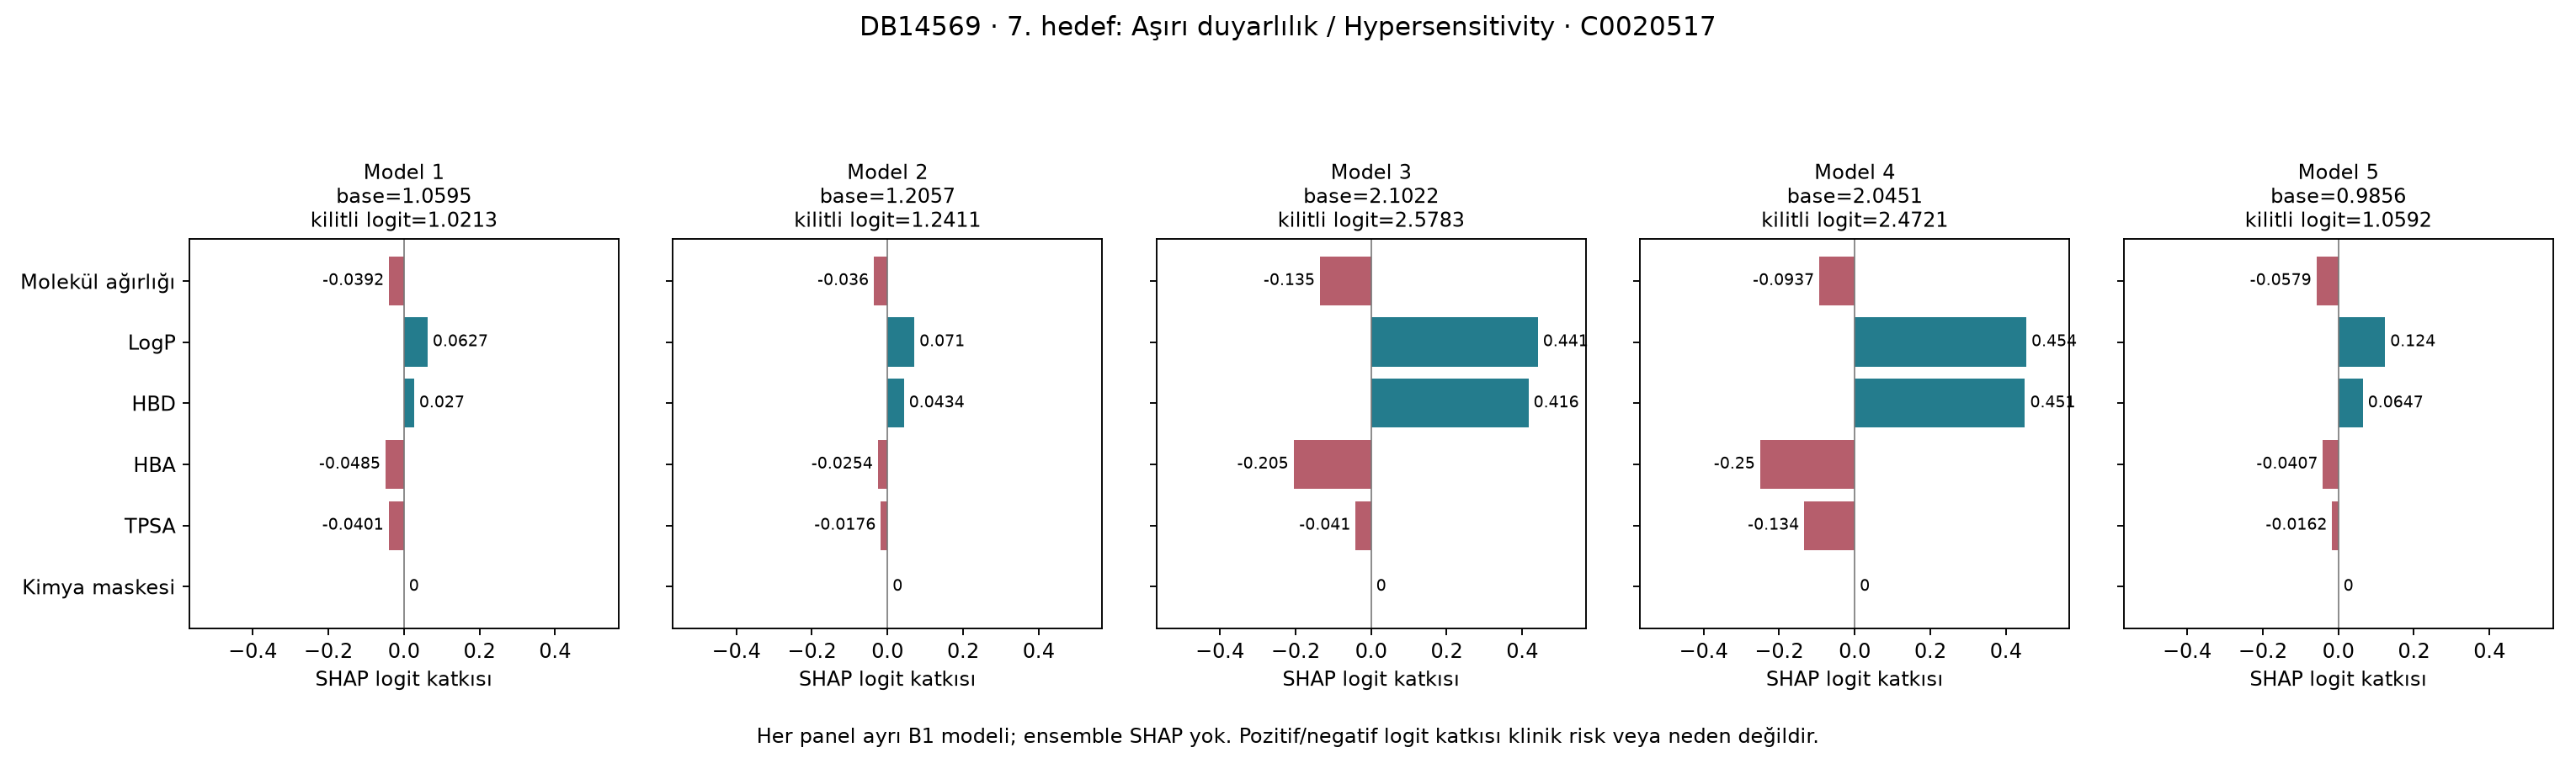

,class_id,term,term_tr_editorial,fold,explanation_tr
0,C0020517,Hypersensitivity,Aşırı duyarlılık,1,"B1 primary model1, Aşırı duyarlılık (Hypersensitivity): train-only background’a göre logiti artı..."
1,C0020517,Hypersensitivity,Aşırı duyarlılık,2,"B1 primary model2, Aşırı duyarlılık (Hypersensitivity): train-only background’a göre logiti artı..."
2,C0020517,Hypersensitivity,Aşırı duyarlılık,3,"B1 primary model3, Aşırı duyarlılık (Hypersensitivity): train-only background’a göre logiti artı..."
3,C0020517,Hypersensitivity,Aşırı duyarlılık,4,"B1 primary model4, Aşırı duyarlılık (Hypersensitivity): train-only background’a göre logiti artı..."
4,C0020517,Hypersensitivity,Aşırı duyarlılık,5,"B1 primary model5, Aşırı duyarlılık (Hypersensitivity): train-only background’a göre logiti artı..."


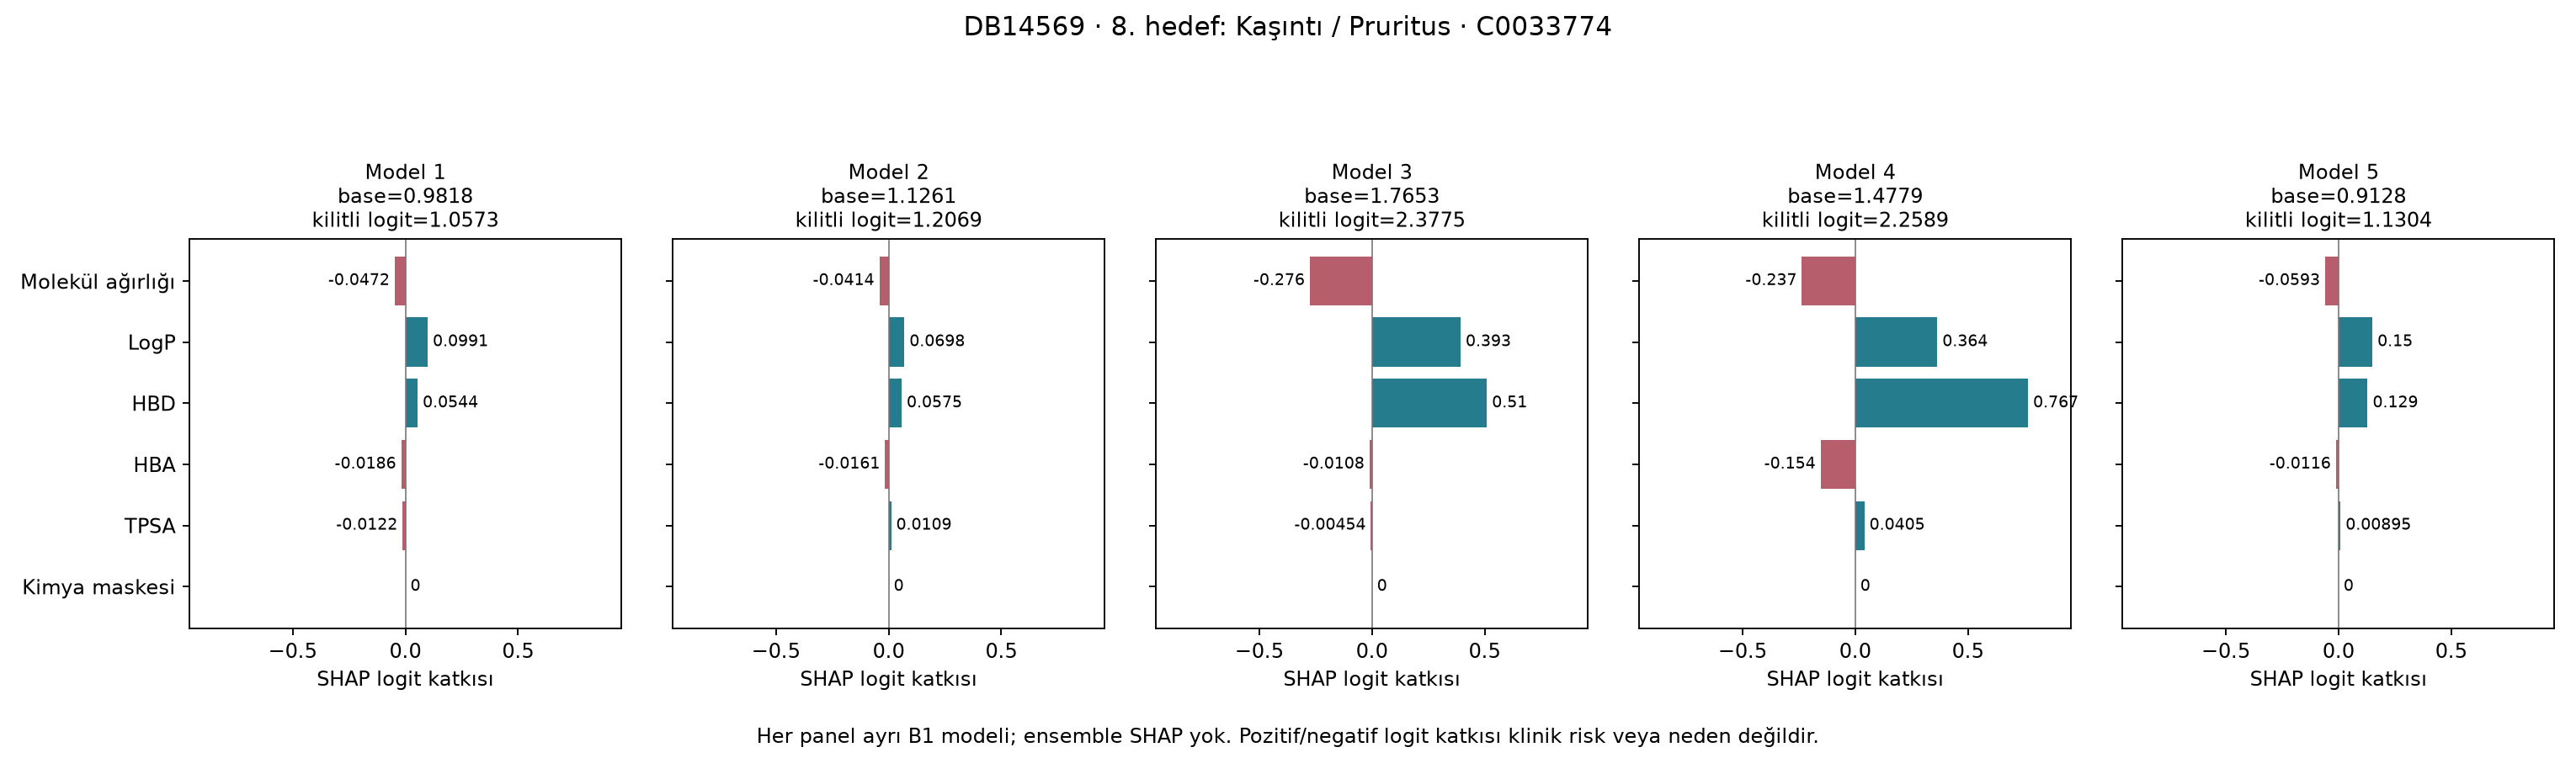

,class_id,term,term_tr_editorial,fold,explanation_tr
0,C0033774,Pruritus,Kaşıntı,1,"B1 primary model1, Kaşıntı (Pruritus): train-only background’a göre logiti artırıcı kimyasal kat..."
1,C0033774,Pruritus,Kaşıntı,2,"B1 primary model2, Kaşıntı (Pruritus): train-only background’a göre logiti artırıcı kimyasal kat..."
2,C0033774,Pruritus,Kaşıntı,3,"B1 primary model3, Kaşıntı (Pruritus): train-only background’a göre logiti artırıcı kimyasal kat..."
3,C0033774,Pruritus,Kaşıntı,4,"B1 primary model4, Kaşıntı (Pruritus): train-only background’a göre logiti artırıcı kimyasal kat..."
4,C0033774,Pruritus,Kaşıntı,5,"B1 primary model5, Kaşıntı (Pruritus): train-only background’a göre logiti artırıcı kimyasal kat..."


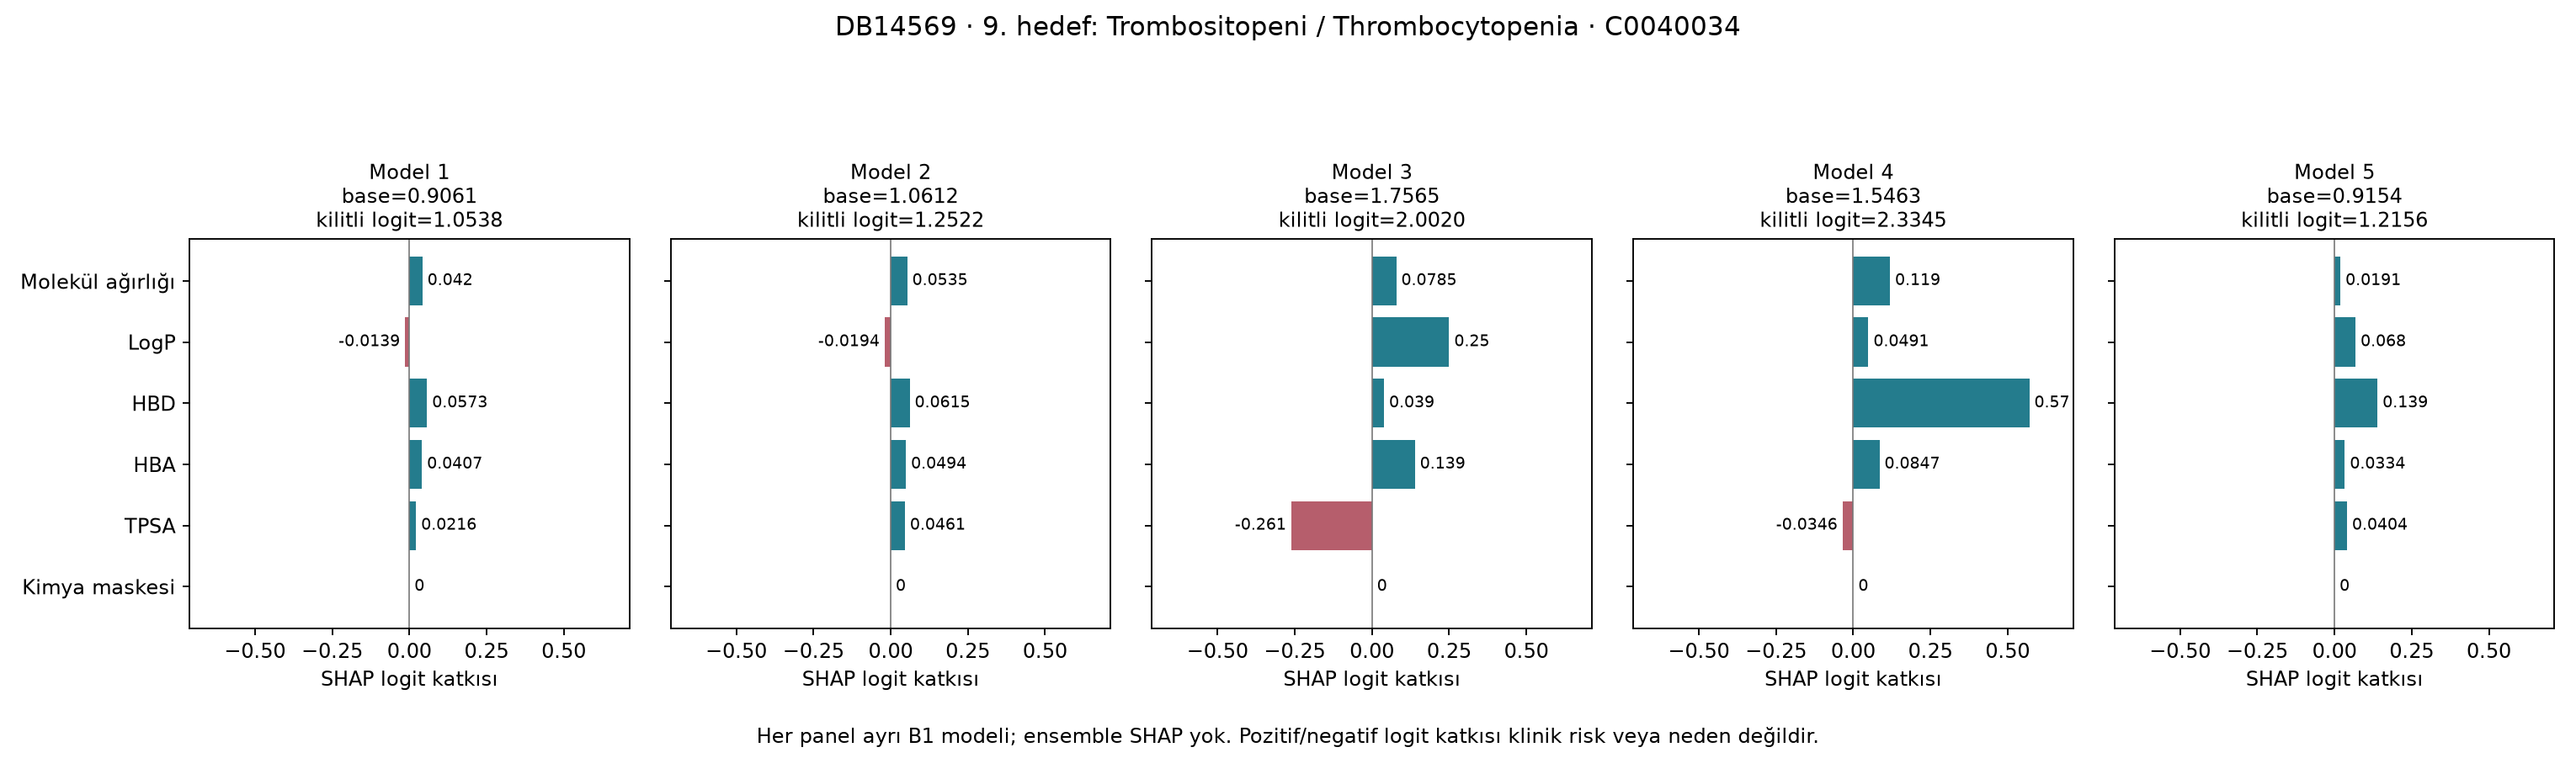

,class_id,term,term_tr_editorial,fold,explanation_tr
0,C0040034,Thrombocytopenia,Trombositopeni,1,"B1 primary model1, Trombositopeni (Thrombocytopenia): train-only background’a göre logiti artırı..."
1,C0040034,Thrombocytopenia,Trombositopeni,2,"B1 primary model2, Trombositopeni (Thrombocytopenia): train-only background’a göre logiti artırı..."
2,C0040034,Thrombocytopenia,Trombositopeni,3,"B1 primary model3, Trombositopeni (Thrombocytopenia): train-only background’a göre logiti artırı..."
3,C0040034,Thrombocytopenia,Trombositopeni,4,"B1 primary model4, Trombositopeni (Thrombocytopenia): train-only background’a göre logiti artırı..."
4,C0040034,Thrombocytopenia,Trombositopeni,5,"B1 primary model5, Trombositopeni (Thrombocytopenia): train-only background’a göre logiti artırı..."


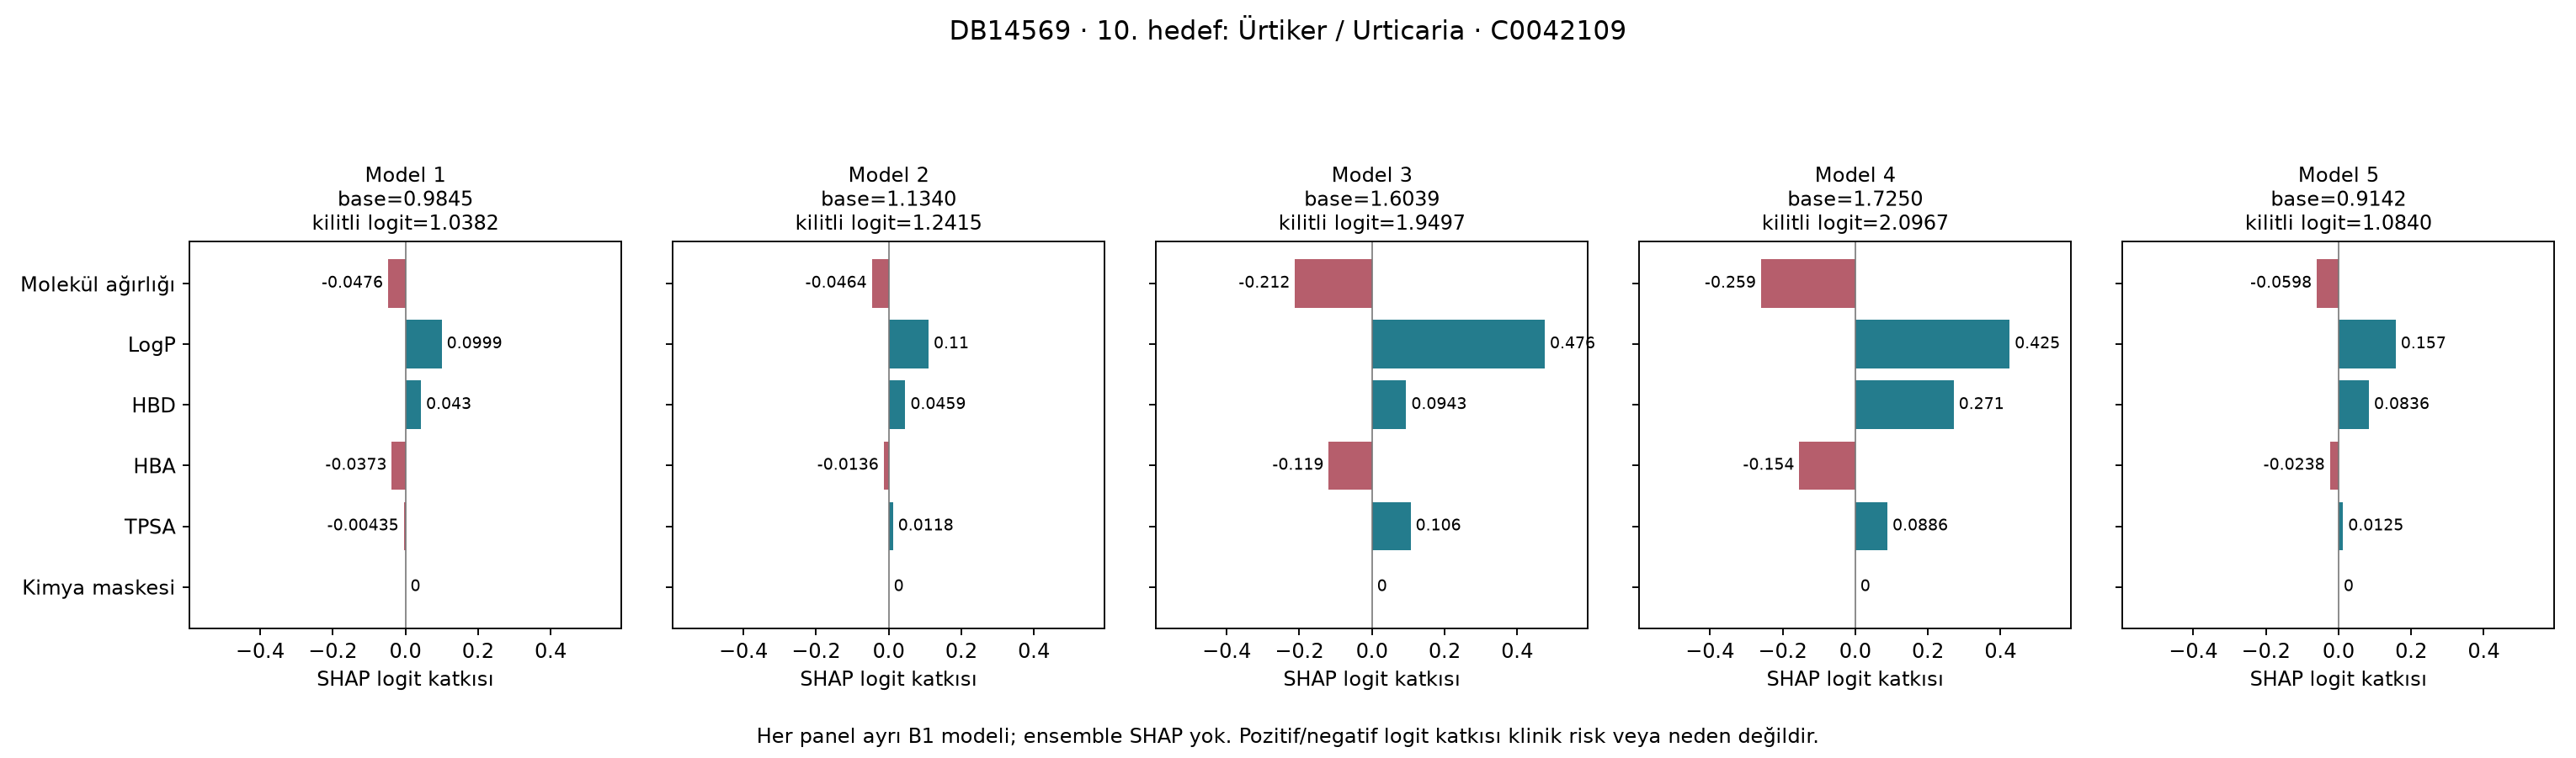

,class_id,term,term_tr_editorial,fold,explanation_tr
0,C0042109,Urticaria,Ürtiker,1,"B1 primary model1, Ürtiker (Urticaria): train-only background’a göre logiti artırıcı kimyasal ka..."
1,C0042109,Urticaria,Ürtiker,2,"B1 primary model2, Ürtiker (Urticaria): train-only background’a göre logiti artırıcı kimyasal ka..."
2,C0042109,Urticaria,Ürtiker,3,"B1 primary model3, Ürtiker (Urticaria): train-only background’a göre logiti artırıcı kimyasal ka..."
3,C0042109,Urticaria,Ürtiker,4,"B1 primary model4, Ürtiker (Urticaria): train-only background’a göre logiti artırıcı kimyasal ka..."
4,C0042109,Urticaria,Ürtiker,5,"B1 primary model5, Ürtiker (Urticaria): train-only background’a göre logiti artırıcı kimyasal ka..."


In [4]:
local=pd.read_csv(r.S/'local_feature_SHAP.csv',float_precision='round_trip')
pairs=pd.read_csv(r.S/'pair_additivity.csv',float_precision='round_trip')
display(pairs)
display(local)
for n in r.read(r.S/'selected_PT_names.json'):
    print(n['rank'],n['term_tr_editorial'],n['class_id'])
    display(Image(filename=str(r.ROOT/f"reports/figures/WP13/tedizolid_B1_SHAP_v1/PT{n['rank']:02d}_{n['class_id']}_five_models.png")))
    display(pd.DataFrame([v for v in r.read(r.S/'Turkish_verbal_explanations.json') if v['class_id']==n['class_id']]))

**Yorum:** Mevcut50 ayrı model/PT açıklaması ve300katkı kullanıldı; yeni SHAP yok. Pozitif/negatif katkı yalnız ilgili B1 logitinin train-background'a göre değişimidir. Maske ayrı tutulur. Ortak sigmoid ortalaması tek doğrusal model gibi açıklanmaz; biyolojik mekanizma veya KÜB bulgusunun nedeni çıkarılmaz.

In [5]:
display(pd.DataFrame([r.read(r.Q/'product_identity_and_limitations.json')]).T)
display(pd.read_csv(r.Q/'human_review_TEMPLATE.csv'))
print((r.Q/'reference_tests.log').read_text(encoding='utf-16') if (r.Q/'reference_tests.log').read_bytes().startswith(b'\xff\xfe') else (r.Q/'reference_tests.log').read_text(encoding='utf-8-sig'))

test_01_original_locks_and_all_source_pins (test_wp13_external_reference_v1.ReferenceTests.test_01_original_locks_and_all_source_pins) ... ok
test_02_preserved_prior_files (test_wp13_external_reference_v1.ReferenceTests.test_02_preserved_prior_files) ... ok
test_03_pdf_copy_equals_user_original (test_wp13_external_reference_v1.ReferenceTests.test_03_pdf_copy_equals_user_original) ... ok
test_04_all_physical_pages_and_text_hashes (test_wp13_external_reference_v1.ReferenceTests.test_04_all_physical_pages_and_text_hashes) ... ok
test_05_every_quote_exact_range (test_wp13_external_reference_v1.ReferenceTests.test_05_every_quote_exact_range) ... ok
test_06_all_table_cells (test_wp13_external_reference_v1.ReferenceTests.test_06_all_table_cells) ... ok
test_07_frequency_column_not_text_order (test_wp13_external_reference_v1.ReferenceTests.test_07_frequency_column_not_text_order) ... ok
test_08_table_geometry_reproducible (test_wp13_external_reference_v1.ReferenceTests.test_08_table_geometry_r

,0
product,SIVEXTRO 200 mg enjeksiyonluk çözelti hazırlamak için liyofilize toz
document_type,Türkçe KÜB
route,intravenous infusion
ingredient,tedizolid fosfat
dose,200 mg/flakon; sulandırıldıktan sonra 50 mg/mL
model_input,DB14569 active TEDIZOLID
reference_product_relation,"Phosphate prodrug → active tedizolid supported pp8,10; not identical molecular representation or..."
DB09042_prediction,NOT_RUN
clinical_product_equivalence,NOT_ESTABLISHED
reference_ADR_evidence,4.8 pooled phase3 oral and/or IV; 662 recipients; not an IV-only incidence table


,rank,class_id,term_tr_editorial,source_terms,relations,source_scopes,terminology_equivalence,product_scope_appropriateness,frequency_interpretation,final_human_decision,reviewer,reviewed_at
0,1,C0011991,İshal,Diyare,SYNONYM_CANDIDATE,PRODUCT_POOLED_ORAL_IV,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING
1,2,C0015230,Döküntü,Döküntü,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING
2,3,C0002792,Anafilaktik şok,NaN,NaN,NaN,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING
3,4,C0042963,Kusma,Kusma,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING
4,5,C0000737,Karın ağrısı,Karın ağrısı,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING
5,6,C0687713,Gastrointestinal ağrı,Karın ağrısı,TARGET_BROADER_CANDIDATE,PRODUCT_POOLED_ORAL_IV,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING
6,7,C0020517,Aşırı duyarlılık,İlaca aşırı duyarlılık,TARGET_BROADER_CANDIDATE,PRODUCT_POOLED_ORAL_IV,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING
7,8,C0033774,Kaşıntı,Prürit | Genel prürit | Alerjik prürit,SYNONYM_CANDIDATE | SOURCE_NARROWER_CANDIDATE,PRODUCT_POOLED_ORAL_IV,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING
8,9,C0040034,Trombositopeni,trombositopeni | platelet düşüşü,TRANSLATION_CANDIDATE | RELATED_DISTINCT,CLASS_OTHER_MEMBER_CONTINUED_FROM_PAGE2 | DRUG_DIRECT_VOLUNTEER,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING
9,10,C0042109,Ürtiker,Ürtiker,TRANSLATION_CANDIDATE,PRODUCT_POOLED_ORAL_IV,PENDING,PENDING,PENDING,PENDING,PENDING,PENDING


**Sonuç:** Kaynak ve sıralama izlenebilir şekilde karşılaştırıldı. Uzman eşleme alt kümesi henüz yok; AP/AUROC/klinik doğruluk yüzdesi hesaplanmadı. Tek molekül ve farklı fosfat ürün belgesi, tam kör veya dış klinik validasyon değildir. İnsan incelemesi beklenir. STOP.

## Nihai teknik kanıt ve gerçek ekranlar

36 kaynak/kilit/izolasyon testi ve7 gerçek Streamlit widget kontrolü PASS. Aşağıdaki görüntüler gerçek localhost arayüzünden alınmıştır; semantik doğruluk veya klinik başarı ölçütü değildir. İlk AppTest false-failure, Markdown metnini incelemeyen test harness sorunuydu; başarısız log korunup okuma kapsamı düzeltilerek ayrı rerun kaydı tutuldu. İnsan incelemesi PENDING. STOP.

test_01_original_locks_and_all_source_pins (test_wp13_external_reference_v1.ReferenceTests.test_01_original_locks_and_all_source_pins) ... ok
test_02_preserved_prior_files (test_wp13_external_reference_v1.ReferenceTests.test_02_preserved_prior_files) ... ok
test_03_pdf_copy_equals_user_original (test_wp13_external_reference_v1.ReferenceTests.test_03_pdf_copy_equals_user_original) ... ok
test_04_all_physical_pages_and_text_hashes (test_wp13_external_reference_v1.ReferenceTests.test_04_all_physical_pages_and_text_hashes) ... ok
test_05_every_quote_exact_range (test_wp13_external_reference_v1.ReferenceTests.test_05_every_quote_exact_range) ... ok
test_06_all_table_cells (test_wp13_external_reference_v1.ReferenceTests.test_06_all_table_cells) ... ok
test_07_frequency_column_not_text_order (test_wp13_external_reference_v1.ReferenceTests.test_07_frequency_column_not_text_order) ... ok
test_08_table_geometry_reproducible (test_wp13_external_reference_v1.ReferenceTests.test_08_table_geometry_r

,case,status
0,mode_added_without_breaking_old_view,PASS
1,C0011991_source_alignment,PASS
2,C0020517_source_alignment,PASS
3,C0040034_source_alignment,PASS
4,C0002792_source_alignment,PASS
5,fifth_model_SHAP_CUI_fold_alignment,PASS
6,return_to_preserved_previous_demo,PASS


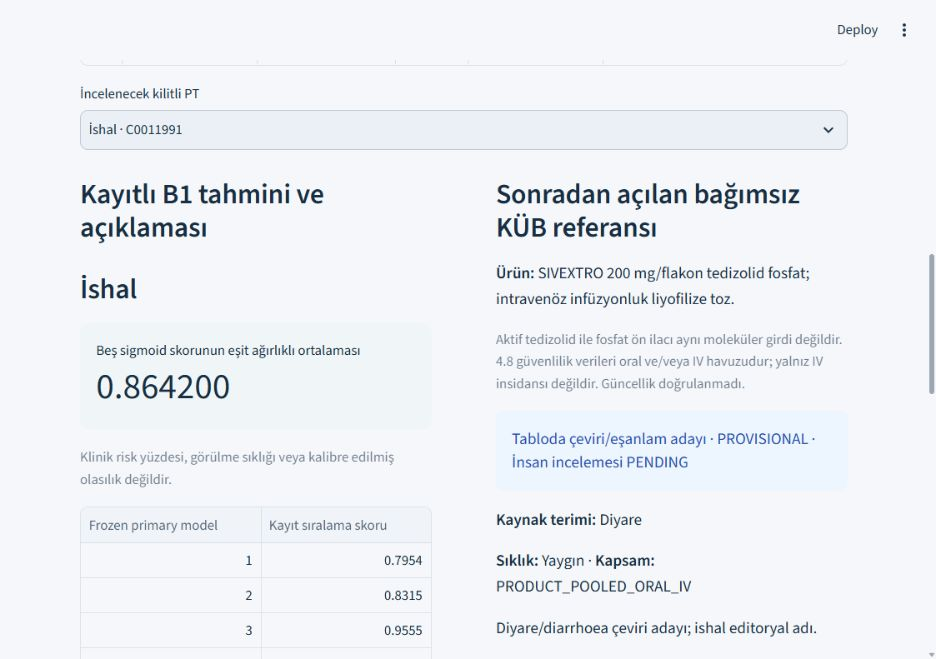

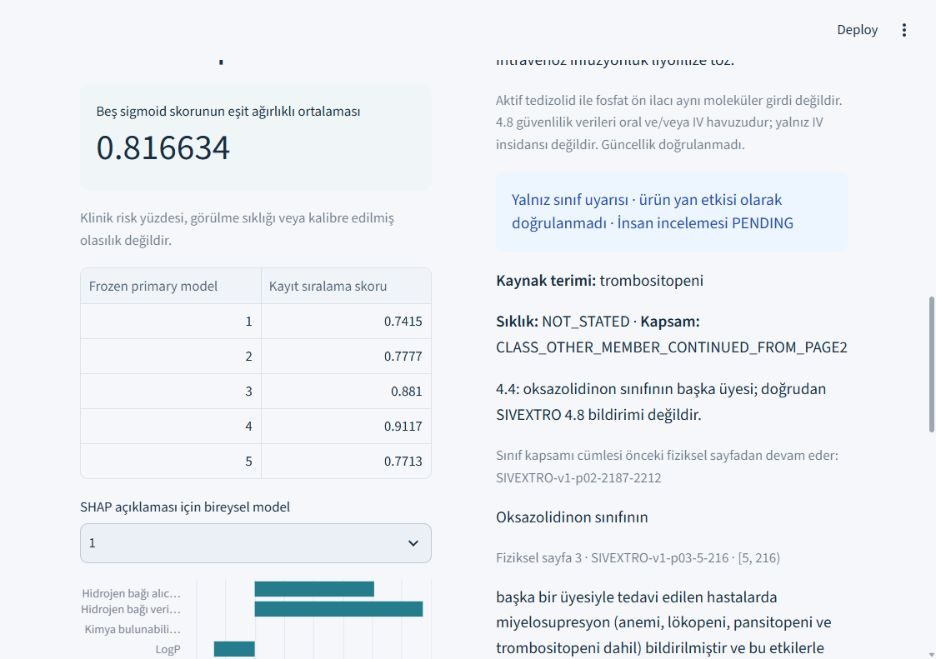

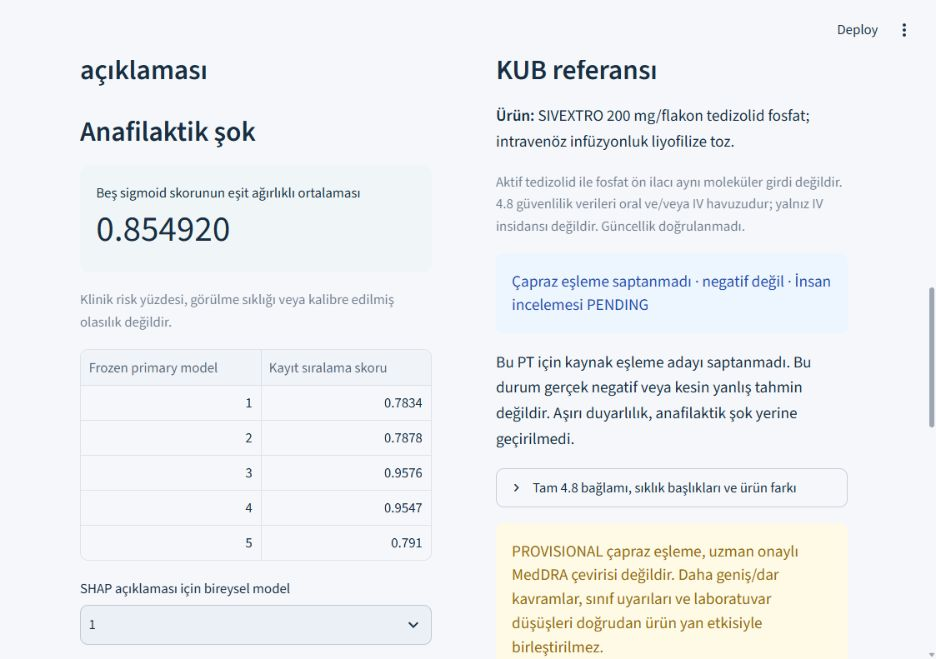

In [6]:
from IPython.display import Image, display
print((r.Q/'reference_tests_final.log').read_text(encoding='utf-8-sig'))
display(pd.DataFrame(r.read(r.Q/'Streamlit_AppTest_results.json')['checks']))
display(Image(filename=str(r.F/'screenshots/04_diarrhoea_two_columns.jpg')))
display(Image(filename=str(r.F/'screenshots/06_thrombocytopenia_class_warning.jpg')))
display(Image(filename=str(r.F/'screenshots/07_anaphylactic_shock_no_crosswalk.jpg')))
